<a href="https://colab.research.google.com/github/DataScience-Fatec-Projects/ICD-004-Analise_de_Algoritmos/blob/main/Aulas/08/atividade05-hash.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Atividade 05 - Hash Table, Hash Map, funções hash e o `dict` do Python**
### Fatec Deputado Ary Fossen - Jundiaí
**Disciplina:** ICD-004 - Análise de Algoritmos

**Integrantes:** Wellington Junior Torres de Melo

---

## Enunciado

> Imagine que seu grupo precisa criar um material didático para um grupo que queira entender o que
> Hash Table, Hash Map e funções Hash, e como a estrutura dicionário funciona em Python.
>
> Para essa demanda crie um relatório didático, explicando esses conceitos e correlacionando com o
> dicionário em Python, mostrando como a estrutura na linguagem funciona por "debaixo dos panos".
>
> Crie um relatório com exemplos no Google Colab, podendo usar mais recursos além de texto e códigos,
> como por exemplo imagens e vídeos.

## Como ler este material

O relatório vai do conceito mais simples ao mais "escondido":

| Seção | Pergunta que responde |
|---|---|
| 1. Por que hashing? | Qual problema essas estruturas resolvem? |
| 2. Funções hash | Como transformar uma chave em um número? |
| 3. Hash Table | Onde guardar esse número, e o que fazer quando dois dão no mesmo lugar? |
| 4. Hash Map | Qual a diferença entre "hash table" e "hash map"? |
| 5. O `dict` por dentro | Como o Python implementa tudo isso de verdade? |
| 6. Lista × dict | Quanto isso vale na prática, medido no relógio? |
| 7. Vídeo e referências | Onde aprofundar? |

Ao longo do texto há **três simuladores interativos** (cards escuros). Eles funcionam direto no
navegador: digite chaves, clique nos botões e observe. Logo abaixo de cada simulador há uma célula de
código Python que **confere** o que o simulador mostrou.

# 0. Preparação do ambiente

Bibliotecas usadas e a identidade visual dos gráficos: cada estrutura tem **uma cor**, usada em todos
os gráficos (azul = lista, laranja = dict).

In [1]:
import hashlib
import os
import random
import string
import subprocess
import sys
import timeit
from collections import Counter

import matplotlib
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# ---------------------------------------------------------------------------
# Identidade visual do relatorio: cada estrutura tem UMA cor, usada em TODOS
# os graficos. (paleta categorica validada para daltonismo)
# ---------------------------------------------------------------------------
COR = {
    "lista": "#2a78d6",     # azul
    "dict": "#eb6834",      # laranja
    "destaque": "#1baf7a",  # verde-agua
}
TINTA = "#0b0b0b"
TINTA_FRACA = "#52514e"


def br(numero, casas=0):
    """Formata um numero no padrao brasileiro: 2.692.537 / 1,618."""
    texto = f"{numero:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def mostrar_simulador(html):
    """Renderiza um simulador interativo (HTML + CSS + JavaScript) na saida da celula."""
    display(HTML(html))


plt.rcParams.update({
    "figure.figsize": (9.0, 4.6),
    "figure.dpi": 110,
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#ffffff",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3",
    "axes.linewidth": 0.8,
    "axes.labelcolor": TINTA_FRACA,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "xtick.color": TINTA_FRACA,
    "ytick.color": TINTA_FRACA,
    "font.size": 10,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "lines.markersize": 5.5,
})

print("Python     :", sys.version.split()[0])
print("matplotlib :", matplotlib.__version__)
print("Algoritmo de hash de str/bytes deste Python:", sys.hash_info.algorithm)

Python     : 3.14.3
matplotlib : 3.10.9
Algoritmo de hash de str/bytes deste Python: siphash13


# 1. Por que hashing?

Quase todo programa precisa responder perguntas do tipo **"dada esta chave, qual é o valor?"**:

- dado o RA, qual é o aluno?
- dada a placa, qual é o veículo?
- dado o nome de uma variável, qual é o valor dela? (o próprio Python faz isso o tempo todo!)

A forma mais ingênua é guardar pares `(chave, valor)` numa **lista** e procurar um a um - a **busca
linear** da Atividade 01, com custo **O(n)**. Se a lista estiver ordenada, dá para usar **busca
binária**, **O(log n)**, mas aí cada inserção custa O(n) para manter a ordem.

A ideia do *hashing* é diferente: em vez de **procurar** onde a chave está, nós **calculamos** onde ela
deveria estar. Uma **função hash** transforma a chave num número, e esse número vira o **índice** de um
vetor. Acessar `vetor[i]` custa **O(1)** - não importa se há 10 ou 10 milhões de itens.

> **Analogia:** numa biblioteca sem organização, você procura o livro prateleira por prateleira (busca
> linear). Com a classificação por assunto, o próprio código do livro diz em qual estante ele está -
> você vai direto. A função hash é esse "código de localização".

In [2]:
agenda_lista = [("Ana", "11 9999-0001"), ("Bruno", "11 9999-0002"), ("Carla", "11 9999-0003"),
                ("Diego", "11 9999-0004"), ("Elisa", "11 9999-0005"), ("Wellington", "11 9999-0006")]


def buscar_na_lista(agenda, nome):
    """Busca linear: compara item por item. Devolve (telefone, comparacoes)."""
    for comparacoes, (chave, valor) in enumerate(agenda, start=1):
        if chave == nome:
            return valor, comparacoes
    return None, len(agenda)


agenda_dict = dict(agenda_lista)          # a mesma agenda, agora como dicionario

for nome in ("Ana", "Wellington", "Zeca"):
    tel, comps = buscar_na_lista(agenda_lista, nome)
    print(f"lista -> {nome:<11} {str(tel):<13} ({comps} comparacoes)")
    print(f"dict  -> {nome:<11} {str(agenda_dict.get(nome)):<13} (1 calculo de hash + acesso direto)\n")

lista -> Ana         11 9999-0001  (1 comparacoes)
dict  -> Ana         11 9999-0001  (1 calculo de hash + acesso direto)

lista -> Wellington  11 9999-0006  (6 comparacoes)
dict  -> Wellington  11 9999-0006  (1 calculo de hash + acesso direto)

lista -> Zeca        None          (6 comparacoes)
dict  -> Zeca        None          (1 calculo de hash + acesso direto)



# 2. Funções hash

Uma **função hash** é qualquer função que recebe um dado de tamanho arbitrário (um texto, um número,
uma tupla, um arquivo...) e devolve um **número inteiro de tamanho fixo**, chamado *hash*, *digest* ou
*resumo*.

$$h:\ \text{chaves} \longrightarrow \{0, 1, 2, \dots, 2^{k}-1\}$$

Para servir a uma tabela hash, ela precisa ter três propriedades:

| Propriedade | O que significa | Por que importa |
|---|---|---|
| **Determinística** | a mesma chave gera **sempre** o mesmo hash | senão guardaríamos num lugar e procuraríamos em outro |
| **Rápida** | custo O(tamanho da chave), sem depender de n | o cálculo do hash é o "preço" de cada acesso |
| **Uniforme** | espalha as chaves igualmente pelos índices | evita que muitas chaves caiam no mesmo lugar (colisões) |

## 2.1 O exemplo da aula: soma dos códigos dos caracteres

A função apresentada em aula soma o código numérico (`ord`) de cada caractere e tira o resto da divisão
pelo tamanho da tabela:

In [3]:
def funcao_hash(chave, tamanho):
    # Converter a chave em numero inteiro baseado na soma dos codigos de caractere
    return sum(ord(char) for char in chave) % tamanho


for nome in ("Wellington", "Gabi", "Aline"):
    soma = sum(ord(c) for c in nome)
    print(f"{nome:<11} soma dos ord = {soma:>5}  ->  {soma} % 5 = indice {funcao_hash(nome, 5)}")

Wellington  soma dos ord =  1059  ->  1059 % 5 = indice 4
Gabi        soma dos ord =   371  ->  371 % 5 = indice 1
Aline       soma dos ord =   489  ->  489 % 5 = indice 4


Ela é determinística e rápida, mas **não é uniforme**. Dois defeitos aparecem logo:

1. **Anagramas sempre colidem** - a soma não liga para a ordem das letras: `"amor"`, `"roma"`,
   `"mora"` e `"ramo"` têm exatamente a mesma soma.
2. **Chaves parecidas se amontoam** - `"aluno0"`, `"aluno1"`, ..., `"aluno999"` só diferem nos dígitos,
   então as somas ficam num intervalo minúsculo e a maioria dos índices nunca é usada.

Uma correção clássica é o **hash polinomial**: cada caractere é multiplicado por uma potência de uma
base (31 é tradicional - é a mesma ideia do `String.hashCode()` do Java):

$$h(s) = s_0 \cdot 31^{L-1} + s_1 \cdot 31^{L-2} + \dots + s_{L-1}$$

Agora a **posição** de cada letra influencia o resultado.

In [4]:
def hash_polinomial(chave, tamanho):
    """h = h*31 + ord(c) para cada caractere; a ordem das letras passa a importar."""
    h = 0
    for c in chave:
        h = h * 31 + ord(c)
    return h % tamanho


print(f"{'chave':<6} | {'soma dos ord':>12} | {'polinomial':>14}")
print("-" * 40)
for palavra in ("amor", "roma", "mora", "ramo"):
    print(f"{palavra:<6} | {funcao_hash(palavra, 10**9):>12} | {hash_polinomial(palavra, 10**9):>14}")

chave  | soma dos ord |     polinomial
----------------------------------------
amor   |          431 |        2998031
roma   |          431 |        3506321
mora   |          431 |        3357521
ramo   |          431 |        3492881


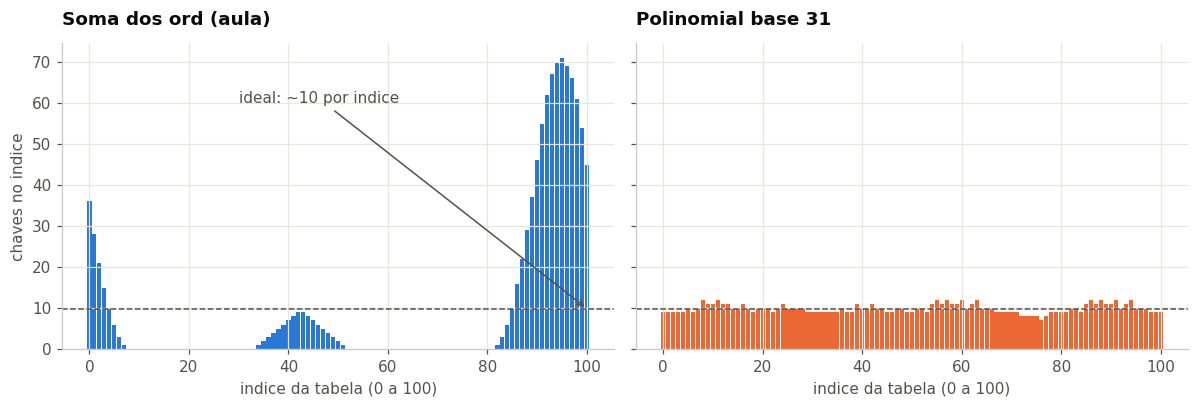

soma dos ord :  45 de 101 indices usados | maior amontoado = 71 chaves
polinomial   : 101 de 101 indices usados | maior amontoado = 12 chaves


In [5]:
M = 101                                       # tabela com 101 posicoes (primo)
chaves = [f"aluno{i}" for i in range(1000)]   # 1000 chaves bem "parecidas"

ocup_soma = Counter(funcao_hash(k, M) for k in chaves)
ocup_poli = Counter(hash_polinomial(k, M) for k in chaves)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, ocup, titulo, cor in ((ax1, ocup_soma, "Soma dos ord (aula)", COR["lista"]),
                              (ax2, ocup_poli, "Polinomial base 31", COR["dict"])):
    ax.bar(range(M), [ocup.get(i, 0) for i in range(M)], color=cor, width=0.85)
    ax.axhline(len(chaves) / M, color=TINTA_FRACA, linestyle="--", linewidth=1)
    ax.set_title(titulo, color=TINTA)
    ax.set_xlabel("indice da tabela (0 a 100)")
ax1.set_ylabel("chaves no indice")
ax1.annotate("ideal: ~10 por indice", xy=(M - 1, len(chaves) / M), xytext=(30, 60),
             color=TINTA_FRACA, arrowprops=dict(arrowstyle="->", color=TINTA_FRACA))
plt.tight_layout()
plt.show()

for nome, ocup in (("soma dos ord", ocup_soma), ("polinomial", ocup_poli)):
    print(f"{nome:<13}: {len(ocup):>3} de {M} indices usados | maior amontoado = {max(ocup.values())} chaves")

O gráfico deixa claro: com a soma, as 1.000 chaves se espremem em poucas dezenas de índices (alguns com
dezenas de chaves); com o polinomial, todos os índices ficam próximos da linha ideal de ~10 chaves.
**A qualidade da função hash decide o desempenho da tabela.**

## 2.2 Hash não criptográfico × hash criptográfico

Existem duas "famílias" de funções hash, com objetivos diferentes:

| | Não criptográfico (tabelas hash) | Criptográfico (segurança) |
|---|---|---|
| Exemplos | `hash()` do Python (SipHash), FNV, MurmurHash, polinomial | SHA-256, SHA-3, BLAKE2 |
| Objetivo | **velocidade** e boa distribuição | ser **impossível de inverter** e de forjar colisões |
| Tamanho do resultado | 32 ou 64 bits | 256 bits ou mais |
| Uso típico | `dict`, `set`, caches, bancos de dados | senhas, assinaturas digitais, blockchain, verificar downloads |

Uma propriedade marcante dos hashes criptográficos é o **efeito avalanche**: mudar **um único bit** da
entrada deve mudar, em média, **metade** dos bits da saída, de forma imprevisível. Assim não dá para
"chegar perto" de um hash alterando a entrada aos poucos.

O simulador abaixo implementa o **SHA-256** completo em JavaScript (as mesmas 64 rodadas do padrão
FIPS 180-4). Digite um texto ou clique em **Mudar 1 letra** e observe quantos bits mudam.

In [6]:
# @title Simulador 2 - SHA-256 e o efeito avalanche { display-mode: "form" }
# Simulador em HTML/CSS/JavaScript puro, sem bibliotecas externas.
# Se ele não aparecer abaixo, execute esta célula (Ctrl+Enter).
HTML_SHA256 = r'''
<div id="hs2">
<style>
#hs2{--bg:#131314;--card:#1e1f20;--campo:#28292a;--borda:#3c4043;--texto:#e3e3e3;--fraco:#9aa0a6;
  --azul:#8ab4f8;--azul-bg:#1b2a4e;--azul-txt:#d2e3fc;--verm:#f28b82;--verm-bg:#4a1512;--verde:#81c995;--amar:#fdd663;
  font-family:"Google Sans","Segoe UI",Roboto,Arial,sans-serif;color:var(--texto);background:var(--bg);
  border-radius:18px;padding:20px;max-width:900px;box-sizing:border-box;line-height:1.4}
#hs2 *{box-sizing:border-box}
#hs2 h3{margin:0 0 4px;font-size:21px;font-weight:400;color:var(--texto)}
#hs2 .sub{color:var(--fraco);font-size:13px;margin-bottom:16px}
#hs2 .rot{font-size:12.5px;color:var(--fraco);margin-bottom:6px}
#hs2 .entrada{display:flex;gap:10px;margin-bottom:6px}
#hs2 input{flex:1;min-width:0;background:var(--card);color:var(--texto);border:1px solid var(--borda);border-radius:999px;padding:12px 18px;font-family:Consolas,"Roboto Mono",monospace;font-size:15px}
#hs2 button{background:var(--campo);color:var(--texto);border:1px solid var(--borda);border-radius:999px;padding:10px 18px;font:inherit;font-size:13.5px;font-weight:500;cursor:pointer;white-space:nowrap}
#hs2 button:hover{border-color:var(--azul)}
#hs2 .compara{font-size:12px;color:var(--fraco);margin:0 4px 14px;font-family:Consolas,monospace;word-break:break-all}
#hs2 .bloco{background:var(--card);border:1px solid var(--borda);border-radius:14px;padding:16px;margin-bottom:14px}
#hs2 .topo{display:flex;justify-content:space-between;align-items:baseline;gap:10px;margin-bottom:12px;flex-wrap:wrap}
#hs2 .topo b{font-weight:500;font-size:15px}
#hs2 .topo .dir{font-family:Consolas,monospace;color:var(--azul);font-size:14px}
#hs2 .topo .dir.it{color:var(--fraco);font-style:italic;font-size:12.5px}
#hs2 .grade3{display:grid;grid-template-columns:repeat(3,1fr);gap:10px}
#hs2 .etapa{border:1px solid var(--azul);border-radius:10px;padding:10px 12px;min-width:0}
#hs2 .etapa span{display:block;font-family:Consolas,monospace;font-size:11px;letter-spacing:1px;color:var(--fraco);margin-bottom:3px}
#hs2 .etapa div{font-family:Consolas,monospace;font-size:13px;overflow:hidden;text-overflow:ellipsis;white-space:nowrap}
#hs2 .etapa small{display:block;color:var(--fraco);font-family:Consolas,monospace;font-size:11px;margin-top:3px;white-space:nowrap;overflow:hidden;text-overflow:ellipsis}
#hs2 .stat{background:var(--campo);border:1px solid var(--borda);border-radius:10px;padding:9px 12px;margin-top:10px}
#hs2 .stat span{display:block;font-size:11.5px;color:var(--fraco)}
#hs2 .stat b{font-family:Consolas,monospace;font-size:16px}
#hs2 .hex{display:flex;flex-wrap:wrap;gap:3px;margin-bottom:6px}
#hs2 .hex i{font-style:normal;font-family:Consolas,monospace;font-size:15px;width:20px;text-align:center;padding:3px 0;border-radius:4px;background:#2a2a2a;color:#777}
#hs2 .hex i.mud{background:var(--verm-bg);color:var(--verm)}
#hs2 .ant{font-family:Consolas,monospace;font-size:11.5px;color:#6f7378;word-break:break-all;margin:4px 0 12px}
#hs2 .bits{display:grid;grid-template-columns:repeat(64,1fr);gap:2px;margin:8px 0 4px}
#hs2 .bits i{display:block;aspect-ratio:1;border-radius:2px;background:#2e2f30}
#hs2 .bits i.mud{background:var(--verm)}
#hs2 .legenda{font-size:11.5px;color:var(--fraco);margin-bottom:12px}
#hs2 .nota{background:#16234a;border:1px solid #2b4a8f;border-radius:10px;padding:10px 14px;font-size:13px;color:var(--azul-txt)}
#hs2 .nota b{color:var(--azul)}
@media (max-width:640px){#hs2 .grade3{grid-template-columns:1fr}#hs2 .bits{grid-template-columns:repeat(32,1fr)}#hs2 .hex i{width:17px;font-size:13px}}
</style>
<h3>Simulador de Hash (SHA-256)</h3>
<div class="sub">Demonstração visual do efeito avalanche em uma função hash criptográfica</div>
<div class="rot">Texto de entrada (digite à vontade: cada tecla é comparada com a versão anterior)</div>
<div class="entrada">
  <input id="hs2-txt" value="abd" spellcheck="false">
  <button id="hs2-mudar">Mudar 1 letra</button>
</div>
<div class="compara" id="hs2-compara"></div>

<div class="bloco">
  <div class="topo"><b>Processamento do bloco</b><span class="dir" id="hs2-resumo"></span></div>
  <div class="grade3">
    <div class="etapa"><span>1. ENTRADA UTF-8</span><div id="hs2-e1"></div><small id="hs2-e1b"></small></div>
    <div class="etapa"><span>2. PREENCHIMENTO</span><div id="hs2-e2"></div><small id="hs2-e2b"></small></div>
    <div class="etapa"><span>3. RODADAS</span><div id="hs2-e3"></div><small>compressão SHA-256</small></div>
  </div>
  <div class="grade3">
    <div class="stat"><span>Bits alterados</span><b id="hs2-bits"></b></div>
    <div class="stat"><span>Taxa de mudança</span><b id="hs2-taxa"></b></div>
    <div class="stat"><span>Efeito avalanche</span><b id="hs2-aval"></b></div>
  </div>
</div>

<div class="bloco">
  <div class="topo"><b>Hash SHA-256 resultante (64 hex / 256 bits)</b><span class="dir it" id="hs2-hexres"></span></div>
  <div class="hex" id="hs2-hex"></div>
  <div class="ant" id="hs2-ant"></div>
  <div class="rot">Mapa dos 256 bits (vermelho = bit que mudou)</div>
  <div class="bits" id="hs2-mapa"></div>
  <div class="legenda">Cada quadradinho é um bit do hash. Repare que os bits alterados ficam espalhados por todo o resultado.</div>
  <div class="nota"><b>Efeito avalanche:</b> alterar uma única letra muda, de forma drástica e imprevisível, cerca de 50% dos bits do hash final.</div>
</div>
<script>
(function () {
  var raiz = document.getElementById('hs2');
  function el(id) { return raiz.querySelector('#hs2-' + id); }
  function esc(t) { return String(t).replace(/[&<>"]/g, function (c) { return {'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;'}[c]; }); }

  // ---------------- SHA-256 (FIPS 180-4) em JavaScript puro ----------------
  // SHA256-INICIO
  var K = [
    0x428a2f98,0x71374491,0xb5c0fbcf,0xe9b5dba5,0x3956c25b,0x59f111f1,0x923f82a4,0xab1c5ed5,
    0xd807aa98,0x12835b01,0x243185be,0x550c7dc3,0x72be5d74,0x80deb1fe,0x9bdc06a7,0xc19bf174,
    0xe49b69c1,0xefbe4786,0x0fc19dc6,0x240ca1cc,0x2de92c6f,0x4a7484aa,0x5cb0a9dc,0x76f988da,
    0x983e5152,0xa831c66d,0xb00327c8,0xbf597fc7,0xc6e00bf3,0xd5a79147,0x06ca6351,0x14292967,
    0x27b70a85,0x2e1b2138,0x4d2c6dfc,0x53380d13,0x650a7354,0x766a0abb,0x81c2c92e,0x92722c85,
    0xa2bfe8a1,0xa81a664b,0xc24b8b70,0xc76c51a3,0xd192e819,0xd6990624,0xf40e3585,0x106aa070,
    0x19a4c116,0x1e376c08,0x2748774c,0x34b0bcb5,0x391c0cb3,0x4ed8aa4a,0x5b9cca4f,0x682e6ff3,
    0x748f82ee,0x78a5636f,0x84c87814,0x8cc70208,0x90befffa,0xa4506ceb,0xbef9a3f7,0xc67178f2];
  function rotr(x, n) { return (x >>> n) | (x << (32 - n)); }
  function sha256Hex(bytes) {
    var l = bytes.length, nBlocos = Math.ceil((l + 9) / 64);
    var buf = new Uint8Array(nBlocos * 64);
    buf.set(bytes);
    buf[l] = 0x80;                                   // bit "1" logo após a mensagem
    var dv = new DataView(buf.buffer), bits = l * 8; // tamanho original nos últimos 64 bits
    dv.setUint32(buf.length - 8, Math.floor(bits / 4294967296));
    dv.setUint32(buf.length - 4, bits >>> 0);
    var H = [0x6a09e667,0xbb67ae85,0x3c6ef372,0xa54ff53a,0x510e527f,0x9b05688c,0x1f83d9ab,0x5be0cd19];
    var W = new Array(64);
    for (var blk = 0; blk < nBlocos; blk++) {
      for (var t = 0; t < 16; t++) W[t] = dv.getUint32(blk * 64 + t * 4);
      for (t = 16; t < 64; t++) {
        var x = W[t - 15], y = W[t - 2];
        var s0 = rotr(x, 7) ^ rotr(x, 18) ^ (x >>> 3);
        var s1 = rotr(y, 17) ^ rotr(y, 19) ^ (y >>> 10);
        W[t] = (W[t - 16] + s0 + W[t - 7] + s1) >>> 0;
      }
      var a = H[0], b = H[1], c = H[2], d = H[3], e = H[4], f = H[5], g = H[6], h = H[7];
      for (t = 0; t < 64; t++) {                     // as 64 rodadas de compressão
        var S1 = rotr(e, 6) ^ rotr(e, 11) ^ rotr(e, 25);
        var ch = (e & f) ^ (~e & g);
        var t1 = (h + S1 + ch + K[t] + W[t]) >>> 0;
        var S0 = rotr(a, 2) ^ rotr(a, 13) ^ rotr(a, 22);
        var maj = (a & b) ^ (a & c) ^ (b & c);
        var t2 = (S0 + maj) >>> 0;
        h = g; g = f; f = e; e = (d + t1) >>> 0; d = c; c = b; b = a; a = (t1 + t2) >>> 0;
      }
      H = [(H[0]+a)>>>0,(H[1]+b)>>>0,(H[2]+c)>>>0,(H[3]+d)>>>0,(H[4]+e)>>>0,(H[5]+f)>>>0,(H[6]+g)>>>0,(H[7]+h)>>>0];
    }
    return H.map(function (v) { return v.toString(16).padStart(8, '0'); }).join('');
  }
  // SHA256-FIM

  var utf8 = new TextEncoder();
  var anterior = 'abc', atual = el('txt').value;

  function bitsDoNibble(hexA, hexB, i) { return parseInt(hexA[i], 16) ^ parseInt(hexB[i], 16); }

  function desenhar() {
    var bytes = utf8.encode(atual), bytesAnt = utf8.encode(anterior);
    var hx = sha256Hex(bytes), hxAnt = sha256Hex(bytesAnt);
    var nBlocos = Math.ceil((bytes.length + 9) / 64);

    var mostra = atual.length > 18 ? atual.slice(0, 18) + '…' : atual;
    el('e1').textContent = '"' + mostra + '" (' + bytes.length * 8 + ' bits)';
    el('e1b').textContent = Array.from(bytes.slice(0, 10)).map(function (v) { return v.toString(16).padStart(2, '0'); }).join(' ') + (bytes.length > 10 ? ' …' : '');
    el('e2').textContent = nBlocos + (nBlocos > 1 ? ' blocos' : ' bloco') + ' × 512 bits';
    el('e2b').textContent = 'msg + "1" + zeros + tamanho (64 bits)';
    el('e3').textContent = '64 × ' + nBlocos + ' = ' + 64 * nBlocos + ' rodadas';

    var difBits = 0, difHex = 0, mapa = '', hexHtml = '';
    for (var i = 0; i < 64; i++) {
      var x = bitsDoNibble(hx, hxAnt, i);
      if (x) difHex++;
      hexHtml += '<i class="' + (x ? 'mud' : '') + '">' + hx[i] + '</i>';
      for (var k = 3; k >= 0; k--) {
        var m = (x >> k) & 1;
        difBits += m;
        mapa += '<i class="' + (m ? 'mud' : '') + '"></i>';
      }
    }
    var taxa = difBits / 256 * 100;
    el('hex').innerHTML = hexHtml;
    el('mapa').innerHTML = mapa;
    el('ant').textContent = 'anterior: ' + hxAnt;
    el('resumo').textContent = difBits + ' bits alterados';
    el('hexres').textContent = difHex + ' de 64 hex alterados (' + taxa.toFixed(0) + '% bits)';
    el('bits').textContent = difBits + ' / 256';
    el('taxa').textContent = taxa.toFixed(1).replace('.', ',') + '%';
    var aval = el('aval');
    if (difBits === 0) { aval.textContent = 'Sem mudança'; aval.style.color = 'var(--fraco)'; }
    else if (taxa >= 40 && taxa <= 60) { aval.textContent = 'Ideal (~50%)'; aval.style.color = 'var(--verde)'; }
    else { aval.textContent = 'Fora de ~50%'; aval.style.color = 'var(--amar)'; }
    el('compara').innerHTML = 'comparando "' + esc(atual) + '" com a versão anterior "' + esc(anterior) + '"';
  }

  function mudarUmaLetra() {
    var letras = 'abcdefghijklmnopqrstuvwxyz';
    var chars = Array.from(atual);
    if (!chars.length) chars = ['a'];
    var i = Math.floor(Math.random() * chars.length), nova;
    do { nova = letras[Math.floor(Math.random() * 26)]; } while (nova === chars[i]);
    chars[i] = nova;
    anterior = atual;
    atual = chars.join('');
    el('txt').value = atual;
    desenhar();
  }

  el('txt').addEventListener('input', function () { anterior = atual; atual = el('txt').value; desenhar(); });
  el('mudar').addEventListener('click', mudarUmaLetra);
  desenhar();
})();
</script>
</div>
'''

mostrar_simulador(HTML_SHA256)

### Conferindo o simulador com o Python

A biblioteca padrão do Python tem o SHA-256 em `hashlib`. Se o simulador estiver correto, os hashes
precisam ser **idênticos** - compare o resultado de `"abc"` e `"abd"` com o que aparece no card acima.

In [7]:
def sha256_hex(texto):
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()


def bits_diferentes(hex_a, hex_b):
    """Quantos dos 256 bits diferem entre dois hashes."""
    return bin(int(hex_a, 16) ^ int(hex_b, 16)).count("1")


h_abc, h_abd = sha256_hex("abc"), sha256_hex("abd")
print("SHA-256('abc') =", h_abc)
print("SHA-256('abd') =", h_abd)
print(f"\nBits diferentes: {bits_diferentes(h_abc, h_abd)} de 256 "
      f"({br(bits_diferentes(h_abc, h_abd) / 256 * 100, 1)}%)")

# Valor oficial do padrao NIST (FIPS 180-4, exemplo "abc")
assert h_abc == "ba7816bf8f01cfea414140de5dae2223b00361a396177a9cb410ff61f20015ad"
print("Confere com o vetor de teste oficial do NIST.")

SHA-256('abc') = ba7816bf8f01cfea414140de5dae2223b00361a396177a9cb410ff61f20015ad
SHA-256('abd') = a52d159f262b2c6ddb724a61840befc36eb30c88877a4030b65cbe86298449c9

Bits diferentes: 122 de 256 (47,7%)
Confere com o vetor de teste oficial do NIST.


### O efeito avalanche em números

Um único exemplo pode ser sorte. Abaixo repetimos o experimento **5.000 vezes**: sorteamos um texto,
trocamos **uma** letra e contamos quantos bits do SHA-256 mudaram. Fazemos o mesmo com o hash
polinomial (truncado em 64 bits) para comparar.

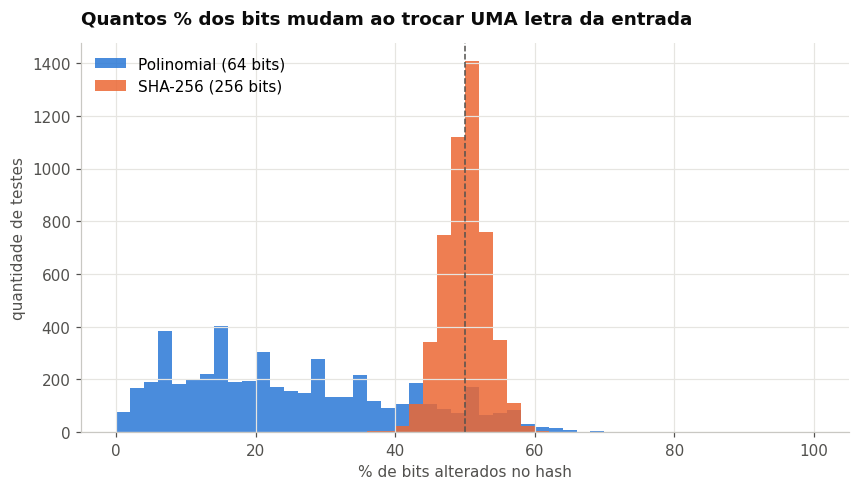

SHA-256   : media de 50,0% dos bits alterados (min 37,9%, max 61,3%)
Polinomial: media de 25,0% dos bits alterados (min 1,6%)


In [8]:
random.seed(2026)
LETRAS = string.ascii_lowercase


def mudar_uma_letra(texto):
    i = random.randrange(len(texto))
    nova = random.choice(LETRAS.replace(texto[i], ""))
    return texto[:i] + nova + texto[i + 1:]


def poli64(texto):
    h = 0
    for c in texto:
        h = (h * 31 + ord(c)) % 2**64
    return h


amostras_sha, amostras_poli = [], []
for _ in range(5000):
    a = "".join(random.choices(LETRAS, k=random.randint(4, 20)))
    b = mudar_uma_letra(a)
    amostras_sha.append(bits_diferentes(sha256_hex(a), sha256_hex(b)) / 256 * 100)
    amostras_poli.append(bin(poli64(a) ^ poli64(b)).count("1") / 64 * 100)

fig, ax = plt.subplots()
ax.hist(amostras_poli, bins=range(0, 101, 2), color=COR["lista"], alpha=0.85, label="Polinomial (64 bits)")
ax.hist(amostras_sha, bins=range(0, 101, 2), color=COR["dict"], alpha=0.85, label="SHA-256 (256 bits)")
ax.axvline(50, color=TINTA_FRACA, linestyle="--", linewidth=1)
ax.set_title("Quantos % dos bits mudam ao trocar UMA letra da entrada", color=TINTA)
ax.set_xlabel("% de bits alterados no hash")
ax.set_ylabel("quantidade de testes")
ax.legend(loc="upper left")
plt.show()

media = lambda xs: sum(xs) / len(xs)
print(f"SHA-256   : media de {br(media(amostras_sha), 1)}% dos bits alterados "
      f"(min {br(min(amostras_sha), 1)}%, max {br(max(amostras_sha), 1)}%)")
print(f"Polinomial: media de {br(media(amostras_poli), 1)}% dos bits alterados "
      f"(min {br(min(amostras_poli), 1)}%)")

O SHA-256 forma um "sino" estreito centrado em **50%**: é o efeito avalanche ideal - **qualquer**
mudança embaralha metade do resultado. O polinomial muda, em média, só um quarto dos bits e com uma
dispersão enorme: trocar a **última** letra altera apenas o valor somado no fim, então às vezes muda 1 ou
2 bits e o hash novo fica "parecido" com o antigo. Para uma tabela hash isso não é problema (basta
espalhar bem), mas para segurança seria fatal. É por isso que tabelas hash usam funções **rápidas**, e senhas
usam funções **criptográficas**.

> **Curiosidade:** o `hash()` que o Python usa para `str` (SipHash-1-3, ver seção 5.3) fica no meio do
> caminho: é rápido, mas recebe uma **chave secreta aleatória** a cada execução, para que um atacante
> não consiga fabricar milhares de chaves que colidem.

# 3. Hash Table (tabela hash)

**Hash table** é a **estrutura de dados** em si: um **vetor de posições** (chamadas *buckets* ou
*slots*) mais uma **função hash** que diz em qual posição cada chave mora.

$$\text{índice} = h(\text{chave}) \bmod m \qquad (m = \text{número de buckets})$$

O `mod m` (resto da divisão) "dobra" um hash enorme para dentro do intervalo `0 .. m-1`.

## 3.1 Colisões são inevitáveis

Se existem infinitas chaves possíveis e só `m` buckets, alguma hora duas chaves diferentes vão dar no
mesmo índice - é o **princípio da casa dos pombos**. Isso se chama **colisão**, e toda tabela hash
precisa de uma estratégia para tratá-la:

| Estratégia | Como funciona | Quem usa |
|---|---|---|
| **Encadeamento** (*separate chaining*) | cada bucket guarda uma **lista ligada**; chaves que colidem entram na mesma lista | `HashMap` do Java, a maioria dos livros-texto |
| **Endereçamento aberto** (*open addressing*) | tudo fica no próprio vetor; se o slot está ocupado, **sonda** outro slot seguindo uma regra | **`dict` e `set` do Python** (seção 5) |

## 3.2 Fator de carga

O desempenho depende de quão cheia a tabela está, medido pelo **fator de carga**:

$$\alpha = \frac{n}{m} = \frac{\text{chaves armazenadas}}{\text{buckets}}$$

Com encadeamento e uma boa função hash, cada lista tem em média $\alpha$ elementos; buscar custa
$O(1 + \alpha)$. Se mantivermos $\alpha$ limitado (por exemplo, $\alpha \le 0{,}75$),
**redimensionando** a tabela quando ela enche, o custo médio é **O(1)**.

No **pior caso** (função hash ruim ou dados maliciosos), todas as chaves caem no mesmo bucket e a
tabela vira uma lista: **O(n)**.

## 3.3 Simulador: inserindo chaves com encadeamento

O simulador usa **exatamente a função da aula** (`sum(ord) % m`). Ele já abre com as três primeiras
chaves processadas - `"Aline"` colide com `"Wellington"` no bucket 4. Experimente:

- clicar em **Próximo** até o fim e ver `"roma"` e `"amor"` (anagramas) caírem juntos;
- trocar para a função **polinomial** com `m = 5`... e perceber que **nada muda** (o porquê está logo
  abaixo do simulador);
- mudar `m` para 11 ou 13, alternar entre as duas funções e observar as colisões e o fator de carga.

In [9]:
# @title Simulador 1 - Tabela hash com encadeamento { display-mode: "form" }
# Simulador em HTML/CSS/JavaScript puro, sem bibliotecas externas.
# Se ele não aparecer abaixo, execute esta célula (Ctrl+Enter).
HTML_TABELA = r'''
<div id="hs1">
<style>
#hs1{--bg:#131314;--card:#1e1f20;--campo:#28292a;--borda:#3c4043;--texto:#e3e3e3;--fraco:#9aa0a6;
  --azul:#8ab4f8;--azul-bg:#1b2a4e;--azul-txt:#d2e3fc;--verm:#f28b82;--verm-bg:#4a1512;--verde:#81c995;
  font-family:"Google Sans","Segoe UI",Roboto,Arial,sans-serif;color:var(--texto);background:var(--bg);
  border-radius:18px;padding:20px;max-width:900px;box-sizing:border-box;line-height:1.4}
#hs1 *{box-sizing:border-box}
#hs1 .cab{background:var(--card);border:1px solid var(--borda);border-radius:14px;padding:14px 18px;margin-bottom:14px}
#hs1 .cab h3{margin:0 0 4px;font-size:19px;font-weight:500;color:var(--texto)}
#hs1 .sub{color:var(--fraco);font-size:13px}
#hs1 .controles{display:flex;flex-wrap:wrap;gap:10px;align-items:flex-end;margin-bottom:14px}
#hs1 label{font-size:12px;color:var(--fraco);display:flex;flex-direction:column;gap:4px}
#hs1 input,#hs1 select{background:var(--campo);color:var(--texto);border:1px solid var(--borda);border-radius:999px;padding:8px 14px;font:inherit;font-size:13px}
#hs1 button{background:var(--campo);color:var(--texto);border:1px solid var(--borda);border-radius:999px;padding:8px 16px;font:inherit;font-size:13px;cursor:pointer}
#hs1 button:hover:not(:disabled){border-color:var(--azul)}
#hs1 button.prim{background:var(--azul-bg);border-color:var(--azul);color:var(--azul-txt)}
#hs1 button:disabled{opacity:.4;cursor:default}
#hs1 .palco{display:grid;grid-template-columns:1fr 1.35fr 1.8fr;background:var(--card);border:1px solid var(--borda);border-radius:14px;padding:16px 4px}
#hs1 .col{padding:0 12px;min-width:0}
#hs1 .col+.col{border-left:1px dashed var(--borda)}
#hs1 .tit{font-family:Consolas,"Roboto Mono",monospace;font-style:italic;letter-spacing:1.5px;font-size:11px;color:var(--fraco);text-align:center;margin-bottom:12px;text-transform:uppercase}
#hs1 .fila{display:flex;flex-direction:column;gap:8px;max-height:380px;overflow:auto;padding:2px}
#hs1 .chip{border:1px solid var(--borda);border-radius:12px;padding:7px;text-align:center;font-size:14px}
#hs1 .chip small{display:block;font-family:Consolas,monospace;font-size:10.5px;color:var(--fraco)}
#hs1 .chip.atual{background:var(--azul-bg);border-color:var(--azul);color:var(--azul-txt)}
#hs1 .chip.feito{opacity:.5}
#hs1 .func{border:1px solid var(--borda);border-radius:16px;padding:14px;text-align:center}
#hs1 .func .nome{font-weight:500;margin-bottom:6px}
#hs1 .mono{font-family:Consolas,"Roboto Mono",monospace}
#hs1 .passo{background:var(--campo);border:1px solid var(--borda);border-radius:10px;padding:8px;margin-top:8px;font-size:12.5px;word-break:break-word;font-family:Consolas,monospace}
#hs1 .passo.res{background:var(--azul-bg);border-color:var(--azul);color:var(--azul-txt)}
#hs1 .vazio{color:var(--fraco);font-size:13px;padding:18px 4px}
#hs1 .baldes{display:flex;flex-direction:column;gap:8px;max-height:400px;overflow:auto;padding:2px}
#hs1 .linha{display:flex;align-items:center;gap:6px;min-height:38px;flex-wrap:wrap}
#hs1 .balde{min-width:58px;text-align:center;border:1px solid var(--borda);border-radius:10px;padding:8px 6px;font-family:Consolas,monospace;color:var(--fraco)}
#hs1 .balde.alvo{border-color:var(--azul);background:var(--azul-bg);color:var(--azul-txt)}
#hs1 .seta{color:var(--fraco);font-family:Consolas,monospace;font-size:12px}
#hs1 .no{border:1px solid var(--borda);border-radius:999px;padding:5px 12px;font-size:12.5px;white-space:nowrap}
#hs1 .no.novo{border-color:var(--verde);color:var(--verde)}
#hs1 .no.colisao{border-color:var(--verm);background:var(--verm-bg);color:#fce8e6}
#hs1 .stats{display:grid;grid-template-columns:repeat(5,1fr);gap:10px;margin-top:14px}
#hs1 .stat{background:var(--card);border:1px solid var(--borda);border-radius:12px;padding:10px 12px}
#hs1 .stat span{display:block;font-size:11.5px;color:var(--fraco)}
#hs1 .stat b{font-family:Consolas,monospace;font-size:17px;font-weight:600}
#hs1 .msg{margin-top:14px;border-left:3px solid var(--azul);background:var(--card);border-radius:10px;padding:12px 16px;font-size:14px;line-height:1.55}
#hs1 .msg.colisao{border-left-color:var(--verm)}
#hs1 .msg code{background:var(--campo);border-radius:6px;padding:1px 6px;font-family:Consolas,monospace}
@media (max-width:720px){
  #hs1 .palco{grid-template-columns:1fr}
  #hs1 .col+.col{border-left:0;border-top:1px dashed var(--borda);padding-top:12px;margin-top:12px}
  #hs1 .stats{grid-template-columns:repeat(2,1fr)}
}
</style>
<div class="cab">
  <h3>Simulador de Tabela Hash</h3>
  <div class="sub">Mapeamento de chaves em buckets e tratamento de colisões por encadeamento (lista ligada)</div>
</div>
<div class="controles">
  <label style="flex:1;min-width:240px">Chaves (separadas por vírgula)
    <input id="hs1-chaves" value="Wellington, Gabi, Aline, Bruno, Carla, Diego, roma, amor"></label>
  <label>Buckets (m)
    <input id="hs1-m" type="number" min="1" max="40" value="5" style="width:84px"></label>
  <label>Função hash
    <select id="hs1-f">
      <option value="soma">Soma dos ord (professor)</option>
      <option value="poli">Polinomial (base 31)</option>
    </select></label>
  <button id="hs1-reset">Reiniciar</button>
  <button id="hs1-passo" class="prim">Próximo &#9654;</button>
  <button id="hs1-tudo">Processar tudo &#9197;</button>
</div>
<div class="palco">
  <div class="col"><div class="tit">Fila de entrada</div><div class="fila" id="hs1-fila"></div></div>
  <div class="col"><div class="tit">Função hash</div><div class="func" id="hs1-func"></div></div>
  <div class="col"><div class="tit">Tabela hash (buckets)</div><div class="baldes" id="hs1-baldes"></div></div>
</div>
<div class="stats" id="hs1-stats"></div>
<div class="msg" id="hs1-msg"></div>
<script>
(function () {
  var raiz = document.getElementById('hs1');
  function el(id) { return raiz.querySelector('#hs1-' + id); }
  function esc(t) { return String(t).replace(/[&<>"]/g, function (c) { return {'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;'}[c]; }); }
  function br(n) { return String(n).replace(/\B(?=(\d{3})+(?!\d))/g, '.'); }

  var estado;

  // Mesma função do exemplo do professor: sum(ord(c) for c in chave)
  function hashSoma(chave) {
    var soma = 0, partes = [];
    for (var c of chave) { var o = c.codePointAt(0); soma += o; partes.push(c + '(' + o + ')'); }
    return { h: BigInt(soma), detalhe: 'soma de ord: ' + partes.join(' + ') };
  }
  // h = h*31 + ord(c) para cada caractere (sem limite de tamanho, como o int do Python)
  function hashPoli(chave) {
    var h = 0n;
    for (var c of chave) { h = h * 31n + BigInt(c.codePointAt(0)); }
    return { h: h, detalhe: 'h = h·31 + ord(c), caractere a caractere' };
  }

  function reiniciar() {
    var chaves = el('chaves').value.split(',').map(function (s) { return s.trim(); }).filter(Boolean);
    var m = Math.max(1, Math.min(40, parseInt(el('m').value, 10) || 1));
    el('m').value = m;
    var baldes = [];
    for (var i = 0; i < m; i++) baldes.push([]);
    estado = { chaves: chaves, m: m, f: el('f').value, pos: 0, baldes: baldes,
               colisoes: 0, inseridas: 0, ultimo: null };
    desenhar();
  }

  function proximo() {
    if (estado.pos >= estado.chaves.length) return;
    var chave = estado.chaves[estado.pos];
    var r = estado.f === 'soma' ? hashSoma(chave) : hashPoli(chave);
    var indice = Number(r.h % BigInt(estado.m));
    var balde = estado.baldes[indice];
    var existente = balde.indexOf(chave) >= 0;
    var colidiu = !existente && balde.length > 0;
    if (!existente) { balde.push(chave); estado.inseridas++; }
    if (colidiu) estado.colisoes++;
    estado.ultimo = { chave: chave, h: r.h, detalhe: r.detalhe, indice: indice,
                      colidiu: colidiu, existente: existente, vizinhos: balde.filter(function (k) { return k !== chave; }) };
    estado.pos++;
    desenhar();
  }

  function desenhar() {
    var e = estado, u = e.ultimo;
    // Fila
    el('fila').innerHTML = e.chaves.map(function (k, i) {
      var cls = i < e.pos - 1 ? 'feito' : (i === e.pos - 1 ? 'atual' : '');
      var rot = i < e.pos ? '[Processado]' : '[Aguardando]';
      return '<div class="chip ' + cls + '">' + esc(k) + '<small>' + rot + '</small></div>';
    }).join('') || '<div class="vazio">Digite algumas chaves acima.</div>';

    // Função hash
    var nomeF = e.f === 'soma' ? 'Hash(chave) % ' + e.m : 'Poli(chave) % ' + e.m;
    if (!u) {
      el('func').innerHTML = '<div class="nome">' + nomeF + '</div><div class="vazio">Clique em <b>Próximo ▶</b> para enviar a primeira chave.</div>';
    } else {
      el('func').innerHTML = '<div class="nome">' + nomeF + '</div>' +
        '<div class="passo">' + esc(u.detalhe) + '</div>' +
        '<div class="passo">Hash("' + esc(u.chave) + '") = ' + br(u.h.toString()) + '</div>' +
        '<div class="passo res">' + br(u.h.toString()) + ' % ' + e.m + ' =<br><b>Índice ' + u.indice + '</b></div>';
    }

    // Buckets
    el('baldes').innerHTML = e.baldes.map(function (b, i) {
      var alvo = u && u.indice === i;
      var nos = b.map(function (k) {
        var cls = '';
        if (alvo && k === u.chave) cls = u.colidiu ? 'colisao' : (u.existente ? '' : 'novo');
        return '<span class="seta">┄▸</span><span class="no ' + cls + '">' + esc(k) + '</span>';
      }).join('');
      return '<div class="linha"><div class="balde' + (alvo ? ' alvo' : '') + '">[ ' + i + ' ]</div>' + nos + '</div>';
    }).join('');

    // Estatísticas
    var maior = Math.max.apply(null, e.baldes.map(function (b) { return b.length; }));
    var usados = e.baldes.filter(function (b) { return b.length; }).length;
    var alfa = (e.inseridas / e.m).toFixed(2).replace('.', ',');
    el('stats').innerHTML =
      '<div class="stat"><span>Chaves inseridas (n)</span><b>' + e.inseridas + '</b></div>' +
      '<div class="stat"><span>Buckets (m)</span><b>' + e.m + '</b></div>' +
      '<div class="stat"><span>Fator de carga α = n/m</span><b>' + alfa + '</b></div>' +
      '<div class="stat"><span>Colisões</span><b>' + e.colisoes + '</b></div>' +
      '<div class="stat"><span>Buckets usados · maior lista</span><b>' + usados + ' · ' + maior + '</b></div>';

    // Mensagem
    var msg = el('msg');
    msg.className = 'msg' + (u && u.colidiu ? ' colisao' : '');
    if (!u) {
      msg.innerHTML = 'Cada chave passa pela <b>função hash</b>, que devolve um número; o resto da divisão por <code>m</code> diz em qual <b>bucket</b> ela mora.';
    } else if (u.existente) {
      msg.innerHTML = '<b>Chave repetida!</b> <code>"' + esc(u.chave) + '"</code> já está no bucket [' + u.indice + ']. Num <code>dict</code> isso apenas <b>atualizaria o valor</b>: chaves são únicas.';
    } else if (u.colidiu) {
      msg.innerHTML = '<b>Colisão detectada!</b> A chave <code>"' + esc(u.chave) + '"</code> gerou o índice <code>' + u.indice +
        '</code>, que já contém ' + u.vizinhos.map(function (k) { return '<code>"' + esc(k) + '"</code>'; }).join(', ') +
        '. Aplicado <b>encadeamento (lista ligada)</b> no bucket [' + u.indice + '].';
    } else {
      msg.innerHTML = '<b>Inserção direta.</b> <code>"' + esc(u.chave) + '"</code> foi para o bucket [' + u.indice + '], que estava vazio.';
    }
    if (e.pos >= e.chaves.length && e.chaves.length) {
      msg.innerHTML += '<br><span style="color:var(--fraco)">Fim da fila. Troque a função hash ou o número de buckets e clique em Reiniciar para comparar.</span>';
    }
    el('passo').disabled = el('tudo').disabled = e.pos >= e.chaves.length;
  }

  el('reset').addEventListener('click', reiniciar);
  el('passo').addEventListener('click', proximo);
  el('tudo').addEventListener('click', function () { while (estado.pos < estado.chaves.length) proximo(); });
  ['chaves', 'm', 'f'].forEach(function (id) { el(id).addEventListener('change', reiniciar); });
  reiniciar();
  // Já abre mostrando as 3 primeiras chaves (a 3ª provoca a primeira colisão).
  for (var i = 0; i < 3; i++) proximo();
})();
</script>
</div>
'''

mostrar_simulador(HTML_TABELA)

### Conferindo o simulador com o Python

Os mesmos índices calculados em Python - eles devem bater com o simulador para `m = 5` e `m = 11`:

In [10]:
CHAVES_SIM = ["Wellington", "Gabi", "Aline", "Bruno", "Carla", "Diego", "roma", "amor"]

print(f"{'':<11} | {'---- m = 5 ----':^17} | {'---- m = 11 ----':^17}")
print(f"{'chave':<11} | {'soma':>7} | {'poli':>7} | {'soma':>7} | {'poli':>7}")
print("-" * 51)
for k in CHAVES_SIM:
    print(f"{k:<11} | {funcao_hash(k, 5):>7} | {hash_polinomial(k, 5):>7} | "
          f"{funcao_hash(k, 11):>7} | {hash_polinomial(k, 11):>7}")

for m in (5, 11):
    for nome, f in (("soma", funcao_hash), ("poli", hash_polinomial)):
        ocupacao = Counter(f(k, m) for k in CHAVES_SIM)
        colisoes = sum(q - 1 for q in ocupacao.values())
        print(f"m = {m:>2}, {nome}: {colisoes} colisoes")

            |  ---- m = 5 ----  | ---- m = 11 ---- 
chave       |    soma |    poli |    soma |    poli
---------------------------------------------------
Wellington  |       4 |       4 |       3 |       4
Gabi        |       1 |       1 |       8 |       4
Aline       |       4 |       4 |       5 |       4
Bruno       |       3 |       3 |       1 |       8
Carla       |       3 |       3 |      10 |       6
Diego       |       3 |       3 |       4 |       7
roma        |       1 |       1 |       2 |       5
amor        |       1 |       1 |       2 |       3
m =  5, soma: 5 colisoes
m =  5, poli: 5 colisoes
m = 11, soma: 1 colisoes
m = 11, poli: 2 colisoes


**Por que, com `m = 5`, a polinomial deu exatamente os mesmos índices da soma?** Porque
$31 \bmod 5 = 1$. Então $31^k \bmod 5 = 1$ para qualquer $k$, e o polinômio inteiro "vira" a soma
dos caracteres quando tiramos o resto por 5:

$$h(s) \bmod 5 = \left(\sum s_i \cdot 31^{k_i}\right) \bmod 5 = \left(\sum s_i \cdot 1\right) \bmod 5$$

O mesmo acontece com qualquer `m` que divida 30 (2, 3, 5, 6, 10, 15, 30). Lição prática: **o tamanho
da tabela também faz parte da função hash**. Por isso livros-texto recomendam `m` primo e "longe" da
base (como 11, 101), enquanto o Python usa potências de 2 e compensa embaralhando os bits do hash
(perturbação, seção 5.3).

Com `m = 11` as duas funções se separam. Com só 8 chaves, a diferença entre elas (1 × 2 colisões) é
puro acaso; a vantagem da polinomial aparece **em volume**, como no gráfico da seção 2.1 - e ela é a
única que separa os anagramas `"roma"` e `"amor"`.

## 3.4 Implementando uma tabela hash com encadeamento

Agora a versão completa, em Python puro, com as quatro operações de um mapa (inserir, buscar, remover,
pertence) e **redimensionamento automático** quando $\alpha$ passa de 0,75. Cada bucket é uma lista
Python fazendo o papel da lista ligada.

In [11]:
class TabelaHashEncadeada:
    """Hash table com encadeamento (separate chaining) e redimensionamento."""

    CARGA_MAXIMA = 0.75

    def __init__(self, m=8, funcao=hash_polinomial):
        self.m = m
        self.funcao = funcao
        self.baldes = [[] for _ in range(m)]   # cada balde: lista de pares [chave, valor]
        self.n = 0
        self.redimensionamentos = 0

    def _indice(self, chave):
        return self.funcao(chave, self.m)

    def __setitem__(self, chave, valor):
        balde = self.baldes[self._indice(chave)]
        for par in balde:
            if par[0] == chave:           # chave ja existe -> so atualiza o valor
                par[1] = valor
                return
        balde.append([chave, valor])      # chave nova -> entra no fim da "lista ligada"
        self.n += 1
        if self.n / self.m > self.CARGA_MAXIMA:
            self._redimensionar(self.m * 2)

    def __getitem__(self, chave):
        for k, v in self.baldes[self._indice(chave)]:
            if k == chave:
                return v
        raise KeyError(chave)

    def __delitem__(self, chave):
        balde = self.baldes[self._indice(chave)]
        for i, (k, _) in enumerate(balde):
            if k == chave:
                del balde[i]
                self.n -= 1
                return
        raise KeyError(chave)

    def __contains__(self, chave):
        try:
            self[chave]
            return True
        except KeyError:
            return False

    def __len__(self):
        return self.n

    def _redimensionar(self, novo_m):
        """Cria um vetor maior e REINSERE tudo: o indice depende de m, entao muda!"""
        antigos = [par for balde in self.baldes for par in balde]
        self.m = novo_m
        self.baldes = [[] for _ in range(novo_m)]
        for k, v in antigos:
            self.baldes[self._indice(k)].append([k, v])
        self.redimensionamentos += 1

    def mostrar(self):
        for i, balde in enumerate(self.baldes):
            cadeia = " -> ".join(f"{k}:{v}" for k, v in balde) or "."
            print(f"  [{i:>2}] {cadeia}")
        print(f"  n = {self.n}, m = {self.m}, fator de carga = {br(self.n / self.m, 2)}")


tabela = TabelaHashEncadeada(m=4)
for nome, idade in [("Wellington", 30), ("Gabi", 25), ("Aline", 28)]:
    tabela[nome] = idade
print("Depois de 3 insercoes:")
tabela.mostrar()

for nome, idade in [("Bruno", 22), ("Carla", 35), ("Diego", 19)]:
    tabela[nome] = idade
print(f"\nDepois de 6 insercoes ({tabela.redimensionamentos} redimensionamento):")
tabela.mostrar()

Depois de 3 insercoes:
  [ 0] .
  [ 1] Gabi:25 -> Aline:28
  [ 2] .
  [ 3] Wellington:30
  n = 3, m = 4, fator de carga = 0,75

Depois de 6 insercoes (1 redimensionamento):
  [ 0] Diego:19
  [ 1] Gabi:25 -> Carla:35
  [ 2] .
  [ 3] .
  [ 4] .
  [ 5] Aline:28
  [ 6] Bruno:22
  [ 7] Wellington:30
  n = 6, m = 8, fator de carga = 0,75


### Teste de corretude contra o `dict` real

Antes de confiar na implementação, fazemos **20.000 operações aleatórias** (inserir, atualizar, remover,
buscar) ao mesmo tempo na nossa tabela e num `dict` do Python. Se em algum momento os dois discordarem,
o `assert` acusa.

In [12]:
random.seed(5)
nossa, referencia = TabelaHashEncadeada(), {}

for _ in range(20_000):
    chave = f"k{random.randrange(3000)}"
    operacao = random.random()
    if operacao < 0.6:
        valor = random.randrange(10**6)
        nossa[chave] = valor
        referencia[chave] = valor
    elif operacao < 0.8 and chave in referencia:
        del nossa[chave]
        del referencia[chave]
    assert (chave in nossa) == (chave in referencia)
    if chave in referencia:
        assert nossa[chave] == referencia[chave]
    assert len(nossa) == len(referencia)

print(f"OK: 20.000 operacoes identicas ao dict. Tamanho final = {len(nossa)} chaves.")
print(f"m final = {nossa.m}, fator de carga = {br(len(nossa) / nossa.m, 2)}, "
      f"redimensionamentos = {nossa.redimensionamentos}")
tamanhos = Counter(len(b) for b in nossa.baldes)
print("Tamanho das listas nos buckets:", dict(sorted(tamanhos.items())))

OK: 20.000 operacoes identicas ao dict. Tamanho final = 2230 chaves.
m final = 4096, fator de carga = 0,54, redimensionamentos = 9
Tamanho das listas nos buckets: {0: 2422, 1: 1188, 2: 416, 3: 70}


Repare na distribuição dos tamanhos das listas: com fator de carga abaixo de 0,75, a grande maioria dos
buckets tem 0, 1 ou 2 elementos. É isso que garante o **O(1) em média**: cada busca percorre uma lista
minúscula, não importa quantas chaves existam no total.

# 4. Hash Map (mapa hash)

Os termos *hash table* e *hash map* são usados quase como sinônimos no dia a dia, mas há uma diferença
de **nível de abstração**:

| | Hash **Map** | Hash **Table** |
|---|---|---|
| O que é | um **tipo abstrato de dados** (TAD): uma coleção de pares **chave → valor** | uma **estrutura de dados** concreta: vetor de buckets + função hash |
| Pergunta que responde | *o que* a estrutura oferece | *como* ela é construída por dentro |
| Operações | `put(k, v)`, `get(k)`, `remove(k)`, `contains(k)` | calcular índice, tratar colisão, redimensionar |
| Outras implementações possíveis | árvore balanceada (`TreeMap` do Java), lista de pares... | também implementa *conjuntos* (`set`), que só têm chaves |

Ou seja: **"mapa"** (ou **dicionário**, ou **array associativo**) é o *contrato*; **"hash"** diz que esse
contrato foi cumprido usando uma *tabela hash*. Um **hash map é um mapa implementado com uma hash table.**

> **Em outras linguagens:** no Java existem as classes `Hashtable` (antiga, sincronizada, não aceita
> `null`) e `HashMap` (moderna, não sincronizada) - aqui os nomes indicam versões diferentes da biblioteca,
> não conceitos diferentes. Em C++ é `std::unordered_map`, em C# `Dictionary<K,V>`, em JavaScript `Map`.

**E no Python?** O `dict` é o **hash map** da linguagem: oferece a interface de mapa
(`d[k] = v`, `d[k]`, `del d[k]`, `k in d`) e, por dentro, é uma **hash table com endereçamento aberto**.
O `set` é a mesma ideia sem os valores.

In [13]:
# A interface de MAPA, oferecida pelo dict...
estoque = {}
estoque["caneta"] = 10          # put
estoque["caderno"] = 4
estoque["caneta"] += 5          # get + put (atualiza, nao duplica)
print("get     :", estoque["caneta"])
print("contains:", "borracha" in estoque)
del estoque["caderno"]          # remove
print("mapa    :", estoque)

# ...e a NOSSA hash table da secao 3 oferece exatamente a mesma interface:
estoque2 = TabelaHashEncadeada()
estoque2["caneta"] = 10
estoque2["caderno"] = 4
estoque2["caneta"] += 5
del estoque2["caderno"]
print("\nnossa tabela:", estoque2["caneta"], "caneta(s);", "borracha" in estoque2)

get     : 15
contains: False
mapa    : {'caneta': 15}

nossa tabela: 15 caneta(s); False


# 5. O `dict` do Python por debaixo dos panos

O `dict` é provavelmente a estrutura mais importante do Python: além de ser usado diretamente, ele
guarda os atributos dos objetos (`obj.__dict__`), as variáveis globais de um módulo (`globals()`), os
argumentos nomeados (`**kwargs`) e muito mais. Por isso ele é **extremamente otimizado**. Vamos abrir a
caixa-preta em quatro partes:

1. a função `hash()` e o que pode ser chave;
2. a aleatoriedade do hash de strings (segurança);
3. a estrutura de memória do CPython (dict compacto + endereçamento aberto);
4. uma evidência medida do redimensionamento.

## 5.1 A função `hash()` e o que pode ser chave

In [14]:
print("hash(42)        =", hash(42))         # inteiros pequenos: o hash e o proprio numero
print("hash(42.0)      =", hash(42.0))       # 42 == 42.0, entao PRECISAM ter o mesmo hash
print("hash(True)      =", hash(True))       # True == 1
print("hash(-1)        =", hash(-1))         # -1 e reservado como codigo de erro em C...
print("hash(-2)        =", hash(-2))         # ...entao hash(-1) vira -2: colisao proposital!
print("hash('Fatec')   =", hash("Fatec"))    # string: numero de 64 bits (muda a cada execucao!)
print("hash((1, 'a'))  =", hash((1, "a")))   # tupla: combina o hash dos elementos

d = {1: "um", 1.0: "um ponto zero", True: "verdadeiro"}
print("\nDict com 1, 1.0 e True como chaves:", d, "-> sao a MESMA chave!")

hash(42)        = 42
hash(42.0)      = 42
hash(True)      = 1
hash(-1)        = -2
hash(-2)        = -2
hash('Fatec')   = 5032094039155488424
hash((1, 'a'))  = 8642757558177612685

Dict com 1, 1.0 e True como chaves: {1: 'verdadeiro'} -> sao a MESMA chave!


Por que `{1: ..., 1.0: ..., True: ...}` virou um dict de **uma** chave só? Porque o `dict` considera duas
chaves iguais quando **`hash(a) == hash(b)` e `a == b`**. Essa é a regra de ouro:

> **Contrato `__hash__` / `__eq__`:** se `a == b`, então obrigatoriamente `hash(a) == hash(b)`.
> (O contrário não vale: hashes iguais podem ser colisão entre objetos diferentes.)

E uma chave precisa ser **hashable** - ter um hash que **nunca muda** enquanto ela estiver no dict.
Por isso objetos **mutáveis** (lista, dict, set) não podem ser chave: se a lista mudasse depois de
inserida, seu hash mudaria e ela ficaria "perdida" no bucket errado.

In [15]:
for candidato in ([1, 2], (1, 2), {"a": 1}, frozenset({1, 2}), (1, [2, 3])):
    try:
        hash(candidato)
        print(f"{str(candidato):<16} -> hashable, pode ser chave")
    except TypeError as erro:
        print(f"{str(candidato):<16} -> TypeError: {erro}")

[1, 2]           -> TypeError: unhashable type: 'list'
(1, 2)           -> hashable, pode ser chave
{'a': 1}         -> TypeError: unhashable type: 'dict'
frozenset({1, 2}) -> hashable, pode ser chave
(1, [2, 3])      -> TypeError: unhashable type: 'list'


### Objetos próprios como chave - e o que acontece com um hash ruim

Classes criadas por nós podem ser chave se definirem `__eq__` e `__hash__` de forma coerente. Para ver
na prática o **pior caso O(n)** da seção 3, criamos duas classes idênticas, exceto pelo `__hash__`:
uma combina os campos (bom), outra devolve **sempre 42** (péssimo - todas as chaves colidem).

In [16]:
class PontoBom:
    __slots__ = ("x", "y")

    def __init__(self, x, y):
        self.x, self.y = x, y

    def __eq__(self, outro):
        return (self.x, self.y) == (outro.x, outro.y)

    def __hash__(self):
        return hash((self.x, self.y))       # combina os campos: espalha bem


class PontoRuim(PontoBom):
    def __hash__(self):
        return 42                           # valido (respeita o contrato), mas TODOS colidem


def tempo_para_inserir(classe, n):
    pontos = [classe(i, i * 7) for i in range(n)]
    return min(timeit.repeat(lambda: {p: None for p in pontos}, number=1, repeat=3))


print(f"{'n':>6} | {'hash bom (ms)':>14} | {'hash = 42 (ms)':>15} | {'vezes mais lento':>17}")
print("-" * 62)
NS_RUIM, t_bom, t_ruim = [250, 500, 1000, 2000], [], []
for n in NS_RUIM:
    tb, tr = tempo_para_inserir(PontoBom, n), tempo_para_inserir(PontoRuim, n)
    t_bom.append(tb)
    t_ruim.append(tr)
    print(f"{n:>6} | {br(tb * 1e3, 3):>14} | {br(tr * 1e3, 1):>15} | {br(tr / tb):>16}x")

     n |  hash bom (ms) |  hash = 42 (ms) |  vezes mais lento
--------------------------------------------------------------
   250 |          0,027 |             2,4 |               88x
   500 |          0,052 |             9,6 |              185x


  1000 |          0,102 |            38,9 |              380x


  2000 |          0,208 |           165,3 |              793x


Com o hash constante, dobrar `n` **quadruplica** o tempo: cada inserção precisa comparar a nova chave
com todas as anteriores (O(n) por inserção, O(n²) no total). O `dict` continua *correto* - só fica lento.
A estrutura é tão boa quanto a sua função hash.

## 5.2 O hash de strings muda a cada execução

Rode a célula abaixo: ela inicia **novos processos Python** e pede o `hash("Fatec")` em cada um.

In [17]:
def hash_em_novo_processo(expressao, seed=None):
    ambiente = dict(os.environ)
    ambiente.pop("PYTHONHASHSEED", None)
    if seed is not None:
        ambiente["PYTHONHASHSEED"] = str(seed)
    saida = subprocess.run([sys.executable, "-c", f"print(hash({expressao}))"],
                           capture_output=True, text=True, env=ambiente)
    return int(saida.stdout)


print("hash('Fatec') em 3 processos diferentes (seed aleatoria):")
for _ in range(3):
    print("   ", hash_em_novo_processo("'Fatec'"))

print("\nCom PYTHONHASHSEED=0 (aleatoriedade desligada), sempre igual:")
for _ in range(2):
    print("   ", hash_em_novo_processo("'Fatec'", seed=0))

print("\nhash(12345) nao depende de seed:", {hash_em_novo_processo("12345") for _ in range(3)})

hash('Fatec') em 3 processos diferentes (seed aleatoria):
    -5303310108026650600
    2805201042832929419
    -5174094559527674638

Com PYTHONHASHSEED=0 (aleatoriedade desligada), sempre igual:
    5453380810583710964
    5453380810583710964



hash(12345) nao depende de seed: {12345}


Isso é **proposital**. Em 2011 foi demonstrado um ataque de negação de serviço (*hash flooding*):
enviando a um servidor web milhares de parâmetros cujos nomes **colidem** de propósito, o `dict` que
guarda esses parâmetros cai no pior caso O(n²) - exatamente o que medimos com o `PontoRuim` - e um
único pedido trava o servidor.

A defesa: a partir do Python 3.3 o hash de `str` e `bytes` recebe uma **semente secreta aleatória** a
cada execução, e desde o Python 3.4 usa o algoritmo **SipHash** (PEP 456; hoje a variante
SipHash-1-3). Sem conhecer a semente, o atacante não consegue prever colisões.

**Consequências práticas:** nunca salve `hash(texto)` em arquivo ou banco esperando o mesmo valor
amanhã; para isso use `hashlib` (seção 2.2).

## 5.3 A estrutura de memória: dict compacto + endereçamento aberto

Desde o Python 3.6, o `dict` do CPython (o interpretador padrão, escrito em C, arquivo
`Objects/dictobject.c`) é formado por **dois vetores**:

```
indices  (tabela hash esparsa, só números pequenos)      entradas (densa, na ORDEM de inserção)
 slot   0    1    2    3    4    5    6    7               pos   hash         chave         valor
     [  .  , 1  ,  . , 0  ,  . ,  . , 2  ,  . ]              0   -918...     'Wellington'    30
                                                             1    533...     'Gabi'          25
  (. = slot vazio)                                           2   -127...     'Aline'         28
```

1. **`indices`** é a tabela hash propriamente dita: um vetor de tamanho potência de 2
   (8, 16, 32, ...) que guarda apenas a **posição** da entrada (ou "vazio" / "removido").
2. **`entradas`** guarda `(hash, chave, valor)` **na ordem em que foram inseridas**. Como novas chaves
   sempre vão para o final, iterar um dict devolve as chaves **na ordem de inserção** - comportamento
   garantido pela linguagem desde o **Python 3.7**.

Vantagens: o vetor esparso guarda inteiros pequenos (1 byte cada, para tabelas pequenas) em vez de
triplas de 24 bytes, então o dict ocupa **bem menos memória**; e a iteração percorre um vetor denso,
sem buracos.

**Colisões: endereçamento aberto com perturbação.** Não há listas ligadas. Para achar o slot de uma
chave, o CPython faz:

```
mascara = tamanho - 1            # tamanho é potência de 2, então  h & mascara == h % tamanho
i       = hash & mascara         # primeiro slot candidato
perturb = hash
enquanto o slot i estiver ocupado por OUTRA chave:
    perturb >>= 5                # vai "injetando" os bits altos do hash
    i = (5*i + 1 + perturb) & mascara
```

A recorrência `5*i + 1` sozinha já visita **todos** os slots de uma tabela potência de 2; o
`perturb` faz com que os bits altos do hash também influenciem o caminho, então duas chaves que
colidem no primeiro slot quase sempre seguem caminhos diferentes depois.

**Remoção:** não dá para simplesmente esvaziar o slot - isso "cortaria" o caminho de sondagem de outras
chaves que passaram por ali. O slot recebe um marcador **`DUMMY`** ("removido"), que a busca pula e que
some no próximo redimensionamento.

**Redimensionamento:** a tabela aceita no máximo **2/3** de ocupação (`USABLE_FRACTION`). Quando enche,
o CPython cria uma tabela nova com o menor tamanho potência de 2 que seja $\geq 3 \times$ o número de
chaves (`GROWTH_RATE`) e reinsere tudo. É um custo O(n) ocasional que, diluído entre todas as inserções,
dá **O(1) amortizado** por inserção.

### Reproduzindo o algoritmo em Python

A classe `DictDidatico` reproduz essa estrutura - os dois vetores, a sondagem com perturbação, o
`DUMMY` e as regras de 2/3 e de crescimento - com as mesmas constantes do código C.

In [18]:
VAZIO, DUMMY = -1, -2        # mesmos codigos do CPython (DKIX_EMPTY, DKIX_DUMMY)
PERTURB_SHIFT = 5
TAMANHO_MINIMO = 8


class DictDidatico:
    """Reproducao didatica do dict compacto do CPython (Objects/dictobject.c)."""

    def __init__(self):
        self.indices = []        # tabela esparsa (comeca sem tabela, como o {} real)
        self.entradas = []       # [hash, chave, valor] na ordem de insercao; None = removida
        self.utilizavel = 0      # quantas insercoes ainda cabem antes de redimensionar
        self.usados = 0          # chaves vivas
        self.historico = []      # (n_antes, tamanho_antigo, tamanho_novo)

    # ---- sondagem ------------------------------------------------------------
    def sequencia_de_sondagem(self, h, quantos=None):
        mascara = len(self.indices) - 1
        perturb = h & 0xFFFF_FFFF_FFFF_FFFF      # em C o hash vira um size_t (sem sinal)
        i = perturb & mascara
        passos = 0
        while quantos is None or passos < quantos:
            yield i
            passos += 1
            perturb >>= PERTURB_SHIFT
            i = (5 * i + 1 + perturb) & mascara

    def _procurar(self, chave, h):
        """Devolve (slot, posicao_em_entradas, sondagens). posicao = VAZIO se nao achou."""
        if not self.indices:
            return None, VAZIO, 0
        for sondagens, slot in enumerate(self.sequencia_de_sondagem(h), start=1):
            ix = self.indices[slot]
            if ix == VAZIO:
                return slot, VAZIO, sondagens
            if ix >= 0:
                h2, k2, _ = self.entradas[ix]
                if h2 == h and (k2 is chave or k2 == chave):   # mesma regra do dict real
                    return slot, ix, sondagens
            # DUMMY ou outra chave: continua sondando

    def _primeiro_livre(self, h):
        for slot in self.sequencia_de_sondagem(h):
            if self.indices[slot] < 0:           # VAZIO ou DUMMY
                return slot

    # ---- operacoes do mapa -----------------------------------------------------
    def __setitem__(self, chave, valor):
        h = hash(chave)
        _, ix, _ = self._procurar(chave, h)
        if ix >= 0:
            self.entradas[ix][2] = valor         # chave existente: so troca o valor
            return
        if self.utilizavel <= 0:
            self._redimensionar()
        self.indices[self._primeiro_livre(h)] = len(self.entradas)
        self.entradas.append([h, chave, valor])
        self.utilizavel -= 1
        self.usados += 1

    def __getitem__(self, chave):
        _, ix, _ = self._procurar(chave, hash(chave))
        if ix < 0:
            raise KeyError(chave)
        return self.entradas[ix][2]

    def __delitem__(self, chave):
        slot, ix, _ = self._procurar(chave, hash(chave))
        if ix < 0:
            raise KeyError(chave)
        self.indices[slot] = DUMMY               # marca o slot como "removido"
        self.entradas[ix] = None                 # a entrada vira um buraco ate o resize
        self.usados -= 1

    def __contains__(self, chave):
        return self._procurar(chave, hash(chave))[1] >= 0

    def __len__(self):
        return self.usados

    def __iter__(self):                          # ordem de insercao = ordem de entradas
        return (e[1] for e in self.entradas if e is not None)

    # ---- redimensionamento -------------------------------------------------------
    def _redimensionar(self):
        minimo = self.usados * 3                 # GROWTH_RATE
        novo = TAMANHO_MINIMO
        while novo < minimo:
            novo *= 2
        self.historico.append((self.usados, len(self.indices), novo))
        vivas = [e for e in self.entradas if e is not None]   # descarta DUMMYs e buracos
        self.indices = [VAZIO] * novo
        self.entradas = []
        for h, k, v in vivas:
            self.indices[self._primeiro_livre(h)] = len(self.entradas)
            self.entradas.append([h, k, v])
        self.utilizavel = (2 * novo) // 3 - len(vivas)       # USABLE_FRACTION = 2/3

    def mostrar(self):
        simb = {VAZIO: ".", DUMMY: "DUMMY"}
        print("  indices :", [simb.get(ix, ix) for ix in self.indices])
        print("  entradas:")
        for pos, e in enumerate(self.entradas):
            if e is None:
                print(f"    {pos}: (removida)")
            else:
                print(f"    {pos}: hash={e[0]:>21}  chave={e[1]!r:<13} valor={e[2]!r}")


dd = DictDidatico()
for nome, idade in [("Wellington", 30), ("Gabi", 25), ("Aline", 28), ("Bruno", 22)]:
    dd[nome] = idade
print("Tabela de 8 slots com 4 chaves:")
dd.mostrar()

h = hash("Aline")
print(f"\nCaminho de sondagem de 'Aline' (hash & 7 = {h & 7}):",
      list(dd.sequencia_de_sondagem(h, quantos=8)))

del dd["Gabi"]
print("\nDepois de del dd['Gabi'] (slot vira DUMMY, entrada vira buraco):")
dd.mostrar()
print("\nOrdem de iteracao:", list(dd), "| 'Aline' in dd:", "Aline" in dd, "| dd['Bruno'] =", dd["Bruno"])

Tabela de 8 slots com 4 chaves:
  indices : ['.', 3, '.', '.', 0, 2, 1, '.']
  entradas:
    0: hash= -7059926491751015972  chave='Wellington'  valor=30
    1: hash=  2176442201507459876  chave='Gabi'        valor=25
    2: hash=  4485173889656659845  chave='Aline'       valor=28
    3: hash=  2321092450144140292  chave='Bruno'       valor=22

Caminho de sondagem de 'Aline' (hash & 7 = 5): [5, 6, 6, 6, 4, 5, 0, 5]

Depois de del dd['Gabi'] (slot vira DUMMY, entrada vira buraco):
  indices : ['.', 3, '.', '.', 0, 2, 'DUMMY', '.']
  entradas:
    0: hash= -7059926491751015972  chave='Wellington'  valor=30
    1: (removida)
    2: hash=  4485173889656659845  chave='Aline'       valor=28
    3: hash=  2321092450144140292  chave='Bruno'       valor=22

Ordem de iteracao: ['Wellington', 'Aline', 'Bruno'] | 'Aline' in dd: True | dd['Bruno'] = 22


> Os números de hash (e, portanto, os slots ocupados) **mudam a cada execução** do notebook, por causa
> da semente aleatória da seção 5.2. A estrutura, a ordem das entradas e as regras não mudam.

O mesmo teste de 20.000 operações aleatórias da seção 3 garante que o `DictDidatico` se comporta como o
`dict` real - inclusive na **ordem de iteração**:

In [19]:
random.seed(7)
nosso, real = DictDidatico(), {}
for _ in range(20_000):
    chave = random.choice([f"k{random.randrange(2000)}", random.randrange(2000), (random.randrange(50), "t")])
    if random.random() < 0.7:
        nosso[chave] = real[chave] = random.random()
    elif chave in real:
        del nosso[chave]
        del real[chave]
    assert (chave in nosso) == (chave in real) and len(nosso) == len(real)

assert list(nosso) == list(real), "ordem de iteracao divergiu!"
assert all(nosso[k] == v for k, v in real.items())
print(f"OK: mesmo conteudo e MESMA ORDEM do dict real ({len(real)} chaves de str, int e tupla).")

OK: mesmo conteudo e MESMA ORDEM do dict real (2701 chaves de str, int e tupla).


## 5.4 Evidência medida: quando o `dict` real redimensiona?

Não temos acesso direto aos vetores internos do `dict`, mas `sys.getsizeof` mostra a memória ocupada.
Quando a tabela cresce, o tamanho **salta em degrau**. Se o `DictDidatico` reproduz as regras certas, os
saltos do dict real devem acontecer **exatamente** nas inserções em que o nosso modelo redimensiona.

In [20]:
N_MAX = 200
real, modelo = {}, DictDidatico()
tamanhos, saltos_reais = [sys.getsizeof(real)], []
for i in range(1, N_MAX + 1):
    antes = sys.getsizeof(real)
    real[i] = None
    modelo[i] = None
    tamanhos.append(sys.getsizeof(real))
    if tamanhos[-1] != antes:
        saltos_reais.append(i)

saltos_modelo = [n_antes + 1 for n_antes, _, _ in modelo.historico]

print(f"{'insercao':>8} | {'tabela':>15} | {'sys.getsizeof':>22}")
print("-" * 53)
for (n_antes, velho, novo), i in zip(modelo.historico, saltos_modelo):
    print(f"{i:>7}ª | {velho:>4} -> {novo:>3} slots | {br(tamanhos[i - 1]):>7} -> {br(tamanhos[i]):>6} bytes")

print("\nSaltos medidos no dict real :", saltos_reais)
print("Saltos previstos pelo modelo:", saltos_modelo)
assert saltos_reais == saltos_modelo
print("Identicos: o modelo reproduz as regras de 2/3 e de crescimento do CPython.")

insercao |          tabela |          sys.getsizeof
-----------------------------------------------------
      1ª |    0 ->   8 slots |      64 ->    224 bytes
      6ª |    8 ->  16 slots |     224 ->    352 bytes
     11ª |   16 ->  32 slots |     352 ->    632 bytes
     22ª |   32 ->  64 slots |     632 ->  1.168 bytes
     43ª |   64 -> 128 slots |   1.168 ->  2.264 bytes
     86ª |  128 -> 256 slots |   2.264 ->  4.688 bytes
    171ª |  256 -> 512 slots |   4.688 ->  9.304 bytes

Saltos medidos no dict real : [1, 6, 11, 22, 43, 86, 171]
Saltos previstos pelo modelo: [1, 6, 11, 22, 43, 86, 171]
Identicos: o modelo reproduz as regras de 2/3 e de crescimento do CPython.


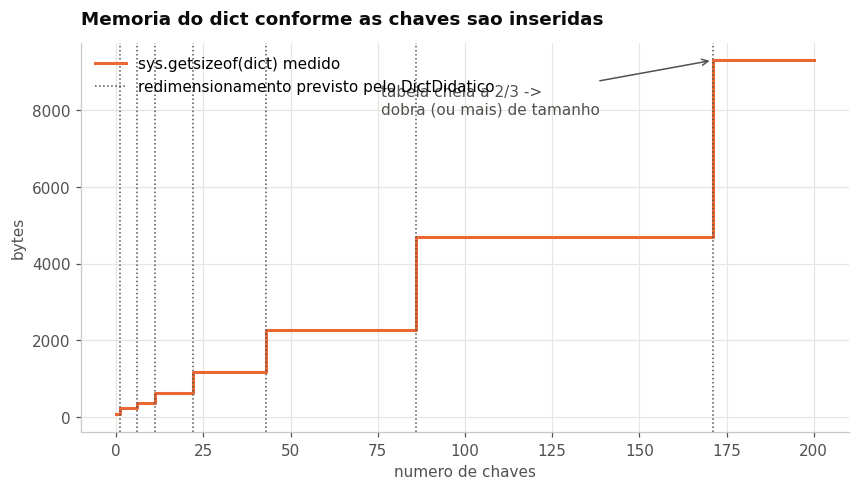

In [21]:
fig, ax = plt.subplots()
ax.step(range(N_MAX + 1), tamanhos, where="post", color=COR["dict"], label="sys.getsizeof(dict) medido")
for i, s in enumerate(saltos_modelo):
    ax.axvline(s, color=TINTA_FRACA, linestyle=":", linewidth=1,
               label="redimensionamento previsto pelo DictDidatico" if i == 0 else None)
ax.set_title("Memoria do dict conforme as chaves sao inseridas", color=TINTA)
ax.set_xlabel("numero de chaves")
ax.set_ylabel("bytes")
ax.legend(loc="upper left")
ax.annotate("tabela cheia a 2/3 ->\ndobra (ou mais) de tamanho", xy=(saltos_modelo[-1], tamanhos[saltos_modelo[-1]]),
            xytext=(saltos_modelo[-1] - 95, tamanhos[-1] * 0.85), color=TINTA_FRACA,
            arrowprops=dict(arrowstyle="->", color=TINTA_FRACA))
plt.show()

Os degraus ficam cada vez **mais largos**: como o tamanho cresce geometricamente (8 → 16 → 32 → 64 ...),
os redimensionamentos ficam cada vez mais raros. Somando o custo de todas as cópias, cada inserção paga
em média uma quantidade constante de trabalho - o **O(1) amortizado**.

## 5.5 Resumo: custo das operações do `dict`

| Operação | Caso médio | Pior caso | Por quê |
|---|---|---|---|
| `d[k]`, `k in d`, `d.get(k)` | **O(1)** | O(n) | hash + poucas sondagens; pior caso = todas colidem |
| `d[k] = v` | **O(1) amortizado** | O(n) | às vezes paga um redimensionamento |
| `del d[k]` | **O(1)** | O(n) | só marca `DUMMY` |
| `for k in d`, `d.copy()` | O(n) | O(n) | percorre o vetor denso de entradas |

**Ligações com o resto da disciplina:**

- o `set` usa a mesma tabela hash com endereçamento aberto, só que sem valores - por isso `x in set` também
  é O(1);
- a **memorização** da Atividade 03 (Fibonacci) era exatamente um `dict` usado como cache: `if n in cache`
  é a consulta O(1) que derrubou o algoritmo de exponencial para linear; o `@lru_cache` também guarda os
  resultados num dict, usando os argumentos como chave - por isso eles precisam ser *hashable*.

# 6. Lista × dict na prática

## 6.1 Simulador: a mesma busca nas duas estruturas

O simulador abaixo faz a mesma pergunta - *"esta chave existe?"* - numa lista e numa tabela hash, passo
a passo e ao mesmo tempo. Para simplificar o desenho ele usa sondagem **linear** (próximo slot) em vez
da perturbação do CPython; a ideia é a mesma.

In [22]:
# @title Simulador 3 - Busca: lista x dicionário { display-mode: "form" }
# Simulador em HTML/CSS/JavaScript puro, sem bibliotecas externas.
# Se ele não aparecer abaixo, execute esta célula (Ctrl+Enter).
HTML_BUSCA = r'''
<div id="hs3">
<style>
#hs3{--bg:#131314;--card:#1e1f20;--campo:#28292a;--borda:#3c4043;--texto:#e3e3e3;--fraco:#9aa0a6;
  --azul:#8ab4f8;--azul-bg:#1b2a4e;--azul-txt:#d2e3fc;--verm:#f28b82;--verm-bg:#4a1512;--verde:#81c995;--verde-bg:#0f3320;
  --lista:#6ea8f0;--dict:#f29a6b;
  font-family:"Google Sans","Segoe UI",Roboto,Arial,sans-serif;color:var(--texto);background:var(--bg);
  border-radius:18px;padding:20px;max-width:900px;box-sizing:border-box;line-height:1.4}
#hs3 *{box-sizing:border-box}
#hs3 .cab{background:var(--card);border:1px solid var(--borda);border-radius:14px;padding:14px 18px;margin-bottom:14px}
#hs3 .cab h3{margin:0 0 4px;font-size:19px;font-weight:500;color:var(--texto)}
#hs3 .sub{color:var(--fraco);font-size:13px}
#hs3 .controles{display:flex;flex-wrap:wrap;gap:10px;align-items:flex-end;margin-bottom:14px}
#hs3 label{font-size:12px;color:var(--fraco);display:flex;flex-direction:column;gap:4px}
#hs3 select{background:var(--campo);color:var(--texto);border:1px solid var(--borda);border-radius:999px;padding:8px 14px;font:inherit;font-size:13px}
#hs3 button{background:var(--campo);color:var(--texto);border:1px solid var(--borda);border-radius:999px;padding:8px 16px;font:inherit;font-size:13px;cursor:pointer}
#hs3 button.prim{background:var(--azul-bg);border-color:var(--azul);color:var(--azul-txt)}
#hs3 button:disabled{opacity:.4;cursor:default}
#hs3 .faixa{background:var(--card);border:1px solid var(--borda);border-radius:14px;padding:14px 16px;margin-bottom:12px}
#hs3 .faixa-topo{display:flex;justify-content:space-between;align-items:baseline;gap:8px;margin-bottom:10px;flex-wrap:wrap}
#hs3 .faixa-topo b{font-weight:500}
#hs3 .tag{font-family:Consolas,monospace;font-size:12px;padding:2px 8px;border-radius:999px;border:1px solid}
#hs3 .tag.l{color:var(--lista);border-color:var(--lista)}
#hs3 .tag.d{color:var(--dict);border-color:var(--dict)}
#hs3 .cont{font-family:Consolas,monospace;font-size:14px;color:var(--fraco)}
#hs3 .cont b{color:var(--texto);font-size:18px}
#hs3 .celulas{display:grid;grid-template-columns:repeat(8,1fr);gap:6px}
#hs3 .cel{border:1px solid var(--borda);border-radius:9px;padding:6px 4px;text-align:center;font-size:12.5px;min-height:46px;transition:all .15s}
#hs3 .cel small{display:block;font-family:Consolas,monospace;font-size:10px;color:var(--fraco)}
#hs3 .cel.vazia{border-style:dashed;color:#5f6368}
#hs3 .cel.olhando{background:var(--azul-bg);border-color:var(--azul);color:var(--azul-txt);transform:scale(1.06)}
#hs3 .cel.visto{opacity:.4}
#hs3 .cel.achou{background:var(--verde-bg);border-color:var(--verde);color:var(--verde);transform:scale(1.06)}
#hs3 .cel.falhou{background:var(--verm-bg);border-color:var(--verm);color:var(--verm)}
#hs3 .calc{font-family:Consolas,monospace;font-size:12.5px;background:var(--campo);border:1px solid var(--borda);border-radius:10px;padding:8px 12px;margin-bottom:10px;min-height:36px}
#hs3 .msg{border-left:3px solid var(--azul);background:var(--card);border-radius:10px;padding:12px 16px;font-size:14px;line-height:1.55}
#hs3 .msg code{background:var(--campo);border-radius:6px;padding:1px 6px;font-family:Consolas,monospace}
@media (max-width:640px){#hs3 .celulas{grid-template-columns:repeat(4,1fr)}}
</style>
<div class="cab">
  <h3>Simulador de Busca: lista × dicionário</h3>
  <div class="sub">A mesma pergunta ("esta chave existe?") respondida por varredura O(n) e por endereço calculado O(1)</div>
</div>
<div class="controles">
  <label>Quantidade de chaves (n)
    <select id="hs3-n"><option value="8">8</option><option value="16" selected>16</option><option value="24">24</option></select></label>
  <label>Chave procurada
    <select id="hs3-alvo"></select></label>
  <label>Velocidade
    <select id="hs3-vel"><option value="450">devagar</option><option value="220" selected>normal</option><option value="80">rápida</option></select></label>
  <button id="hs3-buscar" class="prim">Buscar &#9654;</button>
</div>

<div class="faixa">
  <div class="faixa-topo"><b>Lista <span class="tag l">x in lista</span></b>
    <span class="cont">comparações: <b id="hs3-cl">0</b></span></div>
  <div class="celulas" id="hs3-lista"></div>
</div>

<div class="faixa">
  <div class="faixa-topo"><b>Tabela hash <span class="tag d">x in dict</span></b>
    <span class="cont">operações: <b id="hs3-cd">0</b></span></div>
  <div class="calc" id="hs3-calc">hash(chave) % m → vai direto ao slot</div>
  <div class="celulas" id="hs3-tab"></div>
</div>
<div class="msg" id="hs3-msg"></div>
<script>
(function () {
  var raiz = document.getElementById('hs3');
  function el(id) { return raiz.querySelector('#hs3-' + id); }
  function br(n) { return String(n).replace(/\B(?=(\d{3})+(?!\d))/g, '.'); }
  var NOMES = ['Ana','Bruno','Carla','Diego','Elisa','Fábio','Gabi','Hugo','Iris','João','Lara','Marcos',
               'Nina','Otávio','Paula','Rafa','Sara','Téo','Úrsula','Vitor','Wellington','Xuxa','Yara','Zeca'];
  var AUSENTE = 'Aline';
  var lista, tabela, m, rodando = false, timers = [];

  // hash polinomial (base 31) truncado em 32 bits — didático; o Python usa SipHash
  function hashStr(s) { var h = 0; for (var c of s) h = (Math.imul(h, 31) + c.codePointAt(0)) >>> 0; return h; }

  function montar() {
    timers.forEach(clearTimeout); timers = []; rodando = false;
    var n = parseInt(el('n').value, 10);
    lista = NOMES.slice(0, n);
    m = 1; while (m < n * 1.5) m *= 2;          // mantém a tabela com no máximo ~2/3 ocupada
    tabela = new Array(m).fill(null);
    lista.forEach(function (k) {                // sondagem linear (simplificação didática)
      var i = hashStr(k) % m;
      while (tabela[i] !== null) i = (i + 1) % m;
      tabela[i] = k;
    });
    var atual = el('alvo').value;
    el('alvo').innerHTML = lista.map(function (k) { return '<option>' + k + '</option>'; }).join('') +
      '<option value="' + AUSENTE + '">' + AUSENTE + ' (não existe)</option>';
    el('alvo').value = (lista.indexOf(atual) >= 0 || atual === AUSENTE) ? atual : lista[lista.length - 1];
    desenharBase();
    el('cl').textContent = '0'; el('cd').textContent = '0';
    el('calc').textContent = 'hash(chave) % ' + m + ' → vai direto ao slot';
    el('msg').innerHTML = 'Escolha uma chave e clique em <b>Buscar ▶</b>. A lista confere item por item; a tabela hash calcula o endereço. ' +
      'Dica: escolha a <b>última</b> chave ou uma que <b>não existe</b> para ver o pior caso da lista.';
    el('buscar').disabled = false;
  }

  function desenharBase() {
    el('lista').innerHTML = lista.map(function (k, i) { return '<div class="cel" data-i="' + i + '">' + k + '<small>[' + i + ']</small></div>'; }).join('');
    el('tab').innerHTML = tabela.map(function (k, i) {
      return '<div class="cel' + (k === null ? ' vazia' : '') + '" data-i="' + i + '">' + (k === null ? '—' : k) + '<small>slot ' + i + '</small></div>';
    }).join('');
  }
  function cel(faixa, i) { return el(faixa).querySelector('[data-i="' + i + '"]'); }

  function buscar() {
    if (rodando) return;
    desenharBase();
    rodando = true; el('buscar').disabled = true;
    var alvo = el('alvo').value, vel = parseInt(el('vel').value, 10);
    var passosL = [], passosD = [];

    // Roteiro da lista: compara posição por posição
    for (var i = 0; i < lista.length; i++) { passosL.push(i); if (lista[i] === alvo) break; }
    var achouL = lista.indexOf(alvo) >= 0;

    // Roteiro da tabela: 1 cálculo de hash + sondagens até achar ou cair em slot vazio
    var h = hashStr(alvo), j = h % m, sondas = [];
    while (true) { sondas.push(j); if (tabela[j] === null || tabela[j] === alvo) break; j = (j + 1) % m; }
    var achouD = tabela[sondas[sondas.length - 1]] === alvo;
    passosD.push('hash');
    sondas.forEach(function (s) { passosD.push(s); });

    var total = Math.max(passosL.length, passosD.length);
    for (var t = 0; t < total; t++) {
      (function (t) {
        timers.push(setTimeout(function () {
          if (t < passosL.length) {
            if (t > 0) cel('lista', passosL[t - 1]).className = 'cel visto';
            var c = cel('lista', passosL[t]);
            var fim = t === passosL.length - 1;
            c.className = 'cel ' + (fim ? (achouL ? 'achou' : 'falhou') : 'olhando');
            el('cl').textContent = t + 1;
          }
          if (t < passosD.length) {
            if (passosD[t] === 'hash') {
              el('calc').innerHTML = 'hash("' + alvo + '") = ' + br(h) + ' &nbsp;→&nbsp; ' + br(h) + ' % ' + m + ' = <b>slot ' + (h % m) + '</b>';
            } else {
              if (t > 1) cel('tab', passosD[t - 1]).className = 'cel visto';
              var fimD = t === passosD.length - 1;
              cel('tab', passosD[t]).className = 'cel ' + (fimD ? (achouD ? 'achou' : 'falhou') : 'olhando');
            }
            el('cd').textContent = t + 1;
          }
          if (t === total - 1) concluir(alvo, passosL.length, achouL, sondas.length);
        }, t * vel));
      })(t);
    }
  }

  function concluir(alvo, nL, achou, nS) {
    rodando = false; el('buscar').disabled = false;
    var res = achou ? 'encontraram <code>"' + alvo + '"</code>' : 'concluíram que <code>"' + alvo + '"</code> <b>não existe</b>';
    el('msg').innerHTML = 'As duas estruturas ' + res + '. <b>Lista:</b> ' + nL + ' comparações — cresce junto com n, <b>O(n)</b>. ' +
      '<b>Tabela hash:</b> 1 cálculo de hash + ' + nS + (nS > 1 ? ' sondagens' : ' sondagem') + ' — não depende de n, <b>O(1) em média</b>.<br>' +
      '<span style="color:var(--fraco)">Com 1 milhão de chaves, a lista poderia precisar de 1.000.000 de comparações; a tabela continuaria em ~1–2 sondagens.</span>';
  }

  el('n').addEventListener('change', montar);
  el('alvo').addEventListener('change', function () { if (!rodando) montar(); });
  el('buscar').addEventListener('click', buscar);
  montar();
})();
</script>
</div>
'''

mostrar_simulador(HTML_BUSCA)

## 6.2 Benchmark real: `x in lista` × `x in dict`

Agora no relógio. Para cada tamanho `n`, procuramos o **último** elemento (pior caso da lista) e um
elemento **inexistente**. Metodologia igual à da Atividade 03: `timeit` com várias rodadas, tomando o
**menor** tempo.

In [23]:
NS = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
t_lista, t_dict = [], []

print(f"{'n':>9} | {'lista (us)':>11} | {'dict (us)':>9} | {'dict mais rapido':>17}")
print("-" * 56)
for n in NS:
    lista = list(range(n))
    dicio = dict.fromkeys(lista)
    alvo = n - 1                                  # ultimo elemento: pior caso da lista
    repet = max(1, 200_000 // n)
    tl = min(timeit.repeat(lambda: alvo in lista, number=repet, repeat=5)) / repet
    td = min(timeit.repeat(lambda: alvo in dicio, number=200_000, repeat=5)) / 200_000
    t_lista.append(tl)
    t_dict.append(td)
    print(f"{br(n):>9} | {br(tl * 1e6, 3):>11} | {br(td * 1e6, 3):>9} | {br(tl / td):>16}x")

ausente = -1
print(f"\nChave inexistente com n = {br(NS[-1])}:")
print(f"  lista: {br(min(timeit.repeat(lambda: ausente in lista, number=5, repeat=3)) / 5 * 1e3, 2)} ms")
print(f"  dict : {br(min(timeit.repeat(lambda: ausente in dicio, number=200_000, repeat=3)) / 200_000 * 1e9, 1)} ns")

        n |  lista (us) | dict (us) |  dict mais rapido
--------------------------------------------------------


       10 |       0,065 |     0,028 |                2x


      100 |       0,470 |     0,028 |               17x
    1.000 |       4,437 |     0,031 |              141x
   10.000 |      48,020 |     0,032 |            1.524x
  100.000 |     520,950 |     0,033 |           15.648x


1.000.000 |   5.484,200 |     0,032 |          171.272x

Chave inexistente com n = 1.000.000:


  lista: 5,71 ms
  dict : 33,1 ns


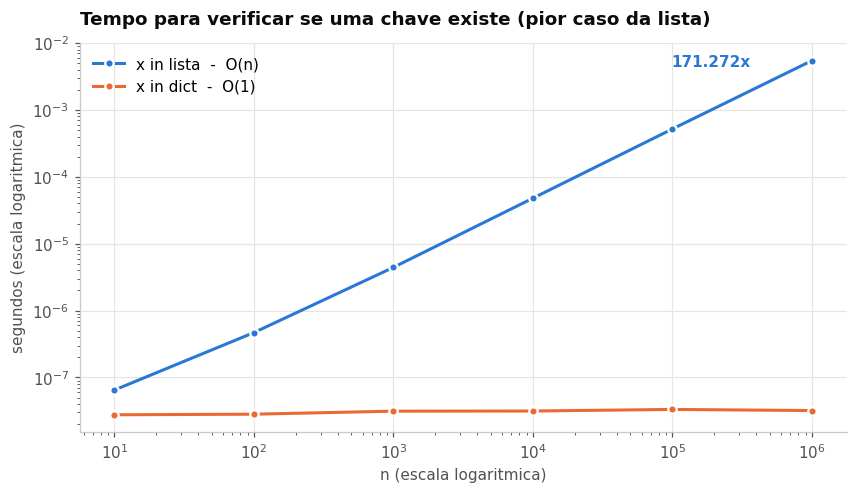

In [24]:
fig, ax = plt.subplots()
ax.plot(NS, t_lista, marker="o", color=COR["lista"], label="x in lista  -  O(n)",
        markeredgecolor="#ffffff", markeredgewidth=1.5)
ax.plot(NS, t_dict, marker="o", color=COR["dict"], label="x in dict  -  O(1)",
        markeredgecolor="#ffffff", markeredgewidth=1.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Tempo para verificar se uma chave existe (pior caso da lista)", color=TINTA)
ax.set_xlabel("n (escala logaritmica)")
ax.set_ylabel("segundos (escala logaritmica)")
ax.legend(loc="upper left")
ax.annotate(f"{br(t_lista[-1] / t_dict[-1])}x", xy=(NS[-1], t_lista[-1]), xytext=(-40, -4),
            textcoords="offset points", ha="right", color=COR["lista"], fontweight="bold")
plt.show()

A linha azul sobe em linha reta no gráfico log-log com inclinação 1: **dez vezes mais dados, dez vezes
mais tempo** - a assinatura do O(n). A linha laranja fica **plana**: o dict responde no mesmo tempo (na
casa de dezenas de nanossegundos) com 10 ou com 1 milhão de chaves.

**O preço:** o dict ocupa mais memória que a lista (os slots vazios dos 2/3, o hash guardado em cada
entrada) e não mantém os dados ordenados por valor. Mais uma vez, a troca clássica da computação:
**gastar memória para ganhar tempo** - a mesma troca da memorização na Atividade 03.

In [25]:
n = 100_000
lista, dicio, conjunto = list(range(n)), dict.fromkeys(range(n)), set(range(n))
print(f"Memoria do 'esqueleto' de cada estrutura com {br(n)} inteiros (sem contar os inteiros):")
for nome, obj in (("list", lista), ("set", conjunto), ("dict", dicio)):
    print(f"  {nome:<5}: {br(sys.getsizeof(obj) / 1024, 0):>6} KiB")

Memoria do 'esqueleto' de cada estrutura com 100.000 inteiros (sem contar os inteiros):
  list :    781 KiB
  set  :  4.096 KiB
  dict :  5.120 KiB


# 7. Para aprofundar

## 7.1 Vídeo: *Modern Python Dictionaries - A confluence of a dozen great ideas*

Palestra de **Raymond Hettinger** (desenvolvedor do núcleo do Python e criador do dict compacto) na
PyCon 2017. Ele reconstrói o `dict` passo a passo, partindo de uma lista de tuplas até chegar na
estrutura da seção 5.3. Em inglês - o YouTube oferece legendas traduzidas automaticamente para
português (⚙ → Legendas → Traduzir automaticamente).

[![Modern Python Dictionaries - Raymond Hettinger - PyCon 2017](https://img.youtube.com/vi/npw4s1QTmPg/hqdefault.jpg)](https://www.youtube.com/watch?v=npw4s1QTmPg)

*Clique na imagem para abrir o vídeo no YouTube.*

## 7.2 Referências

- CORMEN, T. H. et al. **Algoritmos: teoria e prática**. 3. ed. Rio de Janeiro: Elsevier, 2012. Cap. 11 - Tabelas de espalhamento.
- BHARGAVA, A. Y. **Entendendo Algoritmos**. São Paulo: Novatec, 2017. Cap. 5 - Tabelas hash.
- PYTHON SOFTWARE FOUNDATION. *Mapping Types - dict*. https://docs.python.org/3/library/stdtypes.html#mapping-types-dict
- PYTHON SOFTWARE FOUNDATION. *Glossary: hashable*. https://docs.python.org/3/glossary.html#term-hashable
- CPython. *Objects/dictobject.c* (código-fonte do dict). https://github.com/python/cpython/blob/main/Objects/dictobject.c
- PEP 456 - *Secure and interchangeable hash algorithm*. https://peps.python.org/pep-0456/
- NIST. *FIPS 180-4 - Secure Hash Standard (SHA-256)*. https://csrc.nist.gov/pubs/fips/180-4/upd1/final
- HETTINGER, R. *Modern Python Dictionaries* (PyCon 2017). https://www.youtube.com/watch?v=npw4s1QTmPg

---
# 8. Conclusão

| Conceito | Em uma frase | No Python |
|---|---|---|
| **Função hash** | transforma uma chave num número de tamanho fixo, de forma determinística, rápida e bem espalhada | `hash()` (SipHash para `str`); `hashlib` para criptografia |
| **Hash table** | vetor de buckets onde o índice de cada chave é **calculado** (`hash % m`), com uma regra para colisões | a estrutura interna do `dict` e do `set` (endereçamento aberto com perturbação) |
| **Hash map** | o tipo abstrato *chave → valor* implementado com uma hash table | o próprio `dict` |
| **Colisão** | duas chaves no mesmo índice; inevitável, precisa ser tratada | sondagem `i = 5i + 1 + perturb` |
| **Fator de carga** | `n / m`; mantê-lo baixo garante O(1) em média | o dict redimensiona ao passar de **2/3** |

**Por debaixo dos panos, um `d[chave]` no Python faz:**

1. calcula `hash(chave)` (para `str`, com a semente aleatória do processo);
2. pega os bits baixos (`hash & mascara`) para achar o slot no vetor `indices`;
3. se o slot aponta para uma entrada com o mesmo hash **e** chave igual (`==`), devolve o valor;
4. se aponta para outra chave, sonda o próximo slot com a perturbação; se está vazio, a chave não existe.

Tudo isso em tempo **constante em média** - e foi o que medimos: com 1 milhão de elementos, `x in dict`
foi milhares de vezes mais rápido que `x in lista`. O custo é memória extra e a exigência de chaves
*hashable* (imutáveis), e o risco é o pior caso O(n) quando a função hash é ruim - que vimos com o
`PontoRuim` e que o Python combate com hashes aleatorizados.